# Phase 1 — Problem Understanding, Data Understanding, Quality, and Exploratory Analysis

**Project title:** Predicting Recorded Helpful Votes from Review Text and Structured Context

**Selected Amazon Reviews ’23 categories:** `Musical_Instruments` and `Video_Games` ( The procedure for selecting these datasets is completely discussed in another notebook. )

**Main research question**

> Can textual characteristics and structured information about a review, its reviewer, and its product predict the **number of recorded helpful votes**? Will combining text and structured features outperform either source alone?

**Objective A — explanation / EDA:** Study associations between helpful-vote patterns and review text, ratings, purchase verification, publication time, product metadata, and sampled reviewer/product activity.

**Objective B — future modeling:** Estimate the *recorded* number of votes on held-out reviews and evaluate text-only, structured-only, and fused predictors.

### Scope and interpretation

`helpful_vote` is treated as a count recorded in the dataset snapshot. It is not a direct measurement of objective review quality, truthfulness, or the number of votes a review will receive in a future time window. The dataset does not provide the timestamp of each helpful vote, so future vote accrual cannot be reconstructed from this target alone.


**No data is downloaded from the internet.** All data is read from local JSONL/JSONL.GZ files configured in `config/local_settings.json`. This VS Code edition preserves the Phase 1 analysis; only environment-specific setup has changed.



## Reproducible setup and data loading


In [1]:
from pathlib import Path
import sys

# VS Code may run notebooks with the project root or notebooks/ as cwd.
_here = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_here, *_here.parents)
     if (p / "src" / "project_paths.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate src/project_paths.py. Open the extracted project folder in VS Code."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import load_local_settings
from pathlib import Path
import gzip
import json
import random
import re
import hashlib
import warnings
from html import unescape
from html.parser import HTMLParser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = load_local_settings(PROJECT_ROOT)
SEED = LOCAL.seed
REVIEW_SAMPLE_SIZE_PER_CATEGORY = LOCAL.sample_size_per_category
CATEGORIES = LOCAL.categories
SEARCH_ROOTS = list(LOCAL.search_roots)
REVIEW_PATHS = LOCAL.review_paths
META_PATHS = LOCAL.metadata_paths

OUTPUT_DIR = LOCAL.output_root / "phase1_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Project root:", PROJECT_ROOT)
print("Seed:", SEED)
print("Review sample size per category:", REVIEW_SAMPLE_SIZE_PER_CATEGORY)
print("Local data search roots:", [str(p) for p in SEARCH_ROOTS])
print("Output directory:", OUTPUT_DIR)


Project root: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project
Seed: 42
Review sample size per category: 40000
Local data search roots: ['D:\\Uni\\Term 7\\Data Analysis\\Project\\DA_VSCode_Project\\data\\raw']
Output directory: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\outputs\phase1_outputs


In [2]:
def normalized_file_stem(path):
    name = Path(path).name.lower()
    for suffix in (".jsonl.gz", ".jsonl"):
        if name.endswith(suffix):
            name = name[:-len(suffix)]
            break
    return re.sub(r"[^a-z0-9]", "", name)


def find_jsonl_file(category, metadata=False):
    # Manual path overrides automatic discovery.
    manual = META_PATHS[category] if metadata else REVIEW_PATHS[category]
    if manual:
        p = Path(manual)
        if not p.exists():
            raise FileNotFoundError(f"Configured path does not exist: {p}")
        return p

    expected = normalized_file_stem(f"meta_{category}" if metadata else category)
    candidates = []
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for p in root.rglob("*"):
            if p.is_file() and (
                p.name.lower().endswith(".jsonl")
                or p.name.lower().endswith(".jsonl.gz")
            ):
                if normalized_file_stem(p) == expected:
                    candidates.append(p)

    if not candidates:
        return None

    candidates = sorted(candidates, key=lambda p: (len(p.parts), str(p)))
    if len(candidates) > 1:
        print(f"Multiple matches for {category} (metadata={metadata}); using:")
        for p in candidates:
            print("  ", p)
    return candidates[0]


def open_jsonl(path):
    path = Path(path)
    opener = gzip.open if path.name.lower().endswith(".gz") else open
    return opener(path, "rt", encoding="utf-8")


def reservoir_jsonl(path, k, seed):
    # Uniformly sample k valid JSONL records without loading the full file.
    rng = random.Random(seed)
    sample = []
    valid_count = 0
    blank_count = 0
    bad_count = 0

    with open_jsonl(path) as f:
        for line in f:
            if not line.strip():
                blank_count += 1
                continue
            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                bad_count += 1
                continue

            valid_count += 1
            if len(sample) < k:
                sample.append(row)
            else:
                j = rng.randrange(valid_count)
                if j < k:
                    sample[j] = row

    return sample, {
        "valid_rows_scanned": valid_count,
        "sample_rows": len(sample),
        "blank_lines": blank_count,
        "invalid_json_lines": bad_count,
        "sample_fraction": len(sample) / valid_count if valid_count else np.nan,
    }


def first_nonempty(row, keys):
    for key in keys:
        value = row.get(key)
        if value is not None and not (isinstance(value, float) and np.isnan(value)):
            value = str(value).strip()
            if value and value.lower() != "nan":
                return value
    return None


def scan_metadata_for_sample(path, target_keys):
    # Read metadata as a stream and retain only products referenced by sampled reviews.
    records = []
    valid_count = 0
    bad_count = 0
    blank_count = 0

    with open_jsonl(path) as f:
        for line in f:
            if not line.strip():
                blank_count += 1
                continue
            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                bad_count += 1
                continue

            valid_count += 1
            key = first_nonempty(row, ["parent_asin", "asin"])
            if key is not None and key in target_keys:
                records.append(row)

    return records, {
        "valid_rows_scanned": valid_count,
        "matched_metadata_rows_before_deduplication": len(records),
        "blank_lines": blank_count,
        "invalid_json_lines": bad_count,
    }


review_samples = {}
review_file_audit = {}
metadata_records = {}
metadata_file_audit = {}
file_paths = {}

for category in CATEGORIES:
    review_path = find_jsonl_file(category, metadata=False)
    meta_path = find_jsonl_file(category, metadata=True)

    if review_path is None:
        raise FileNotFoundError(
            f"Could not find the review file for {category} under {SEARCH_ROOTS}. "
            "Check config/local_settings.json: data_roots or review_paths."
        )

    file_paths[(category, "reviews")] = review_path
    file_paths[(category, "metadata")] = meta_path

    rows, audit = reservoir_jsonl(
        review_path, k=REVIEW_SAMPLE_SIZE_PER_CATEGORY, seed=SEED
    )
    review_samples[category] = rows
    review_file_audit[category] = audit

    if meta_path is not None:
        sample_keys = {
            first_nonempty(row, ["parent_asin", "asin"]) for row in rows
        }
        sample_keys.discard(None)
        meta_rows, meta_audit = scan_metadata_for_sample(meta_path, sample_keys)
        metadata_records[category] = meta_rows
        metadata_file_audit[category] = meta_audit
    else:
        metadata_records[category] = []
        metadata_file_audit[category] = {
            "valid_rows_scanned": np.nan,
            "matched_metadata_rows_before_deduplication": 0,
            "blank_lines": np.nan,
            "invalid_json_lines": np.nan,
        }

    print(f"\n{category}")
    print("Review file:", review_path)
    print("Metadata file:", meta_path if meta_path else "NOT FOUND")
    print("Review audit:", audit)
    print("Metadata audit:", metadata_file_audit[category])


Musical_Instruments
Review file: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\Musical_Instruments.jsonl.gz
Metadata file: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\meta_Musical_Instruments.jsonl.gz
Review audit: {'valid_rows_scanned': 3017439, 'sample_rows': 40000, 'blank_lines': 0, 'invalid_json_lines': 0, 'sample_fraction': 0.013256274609031036}
Metadata audit: {'valid_rows_scanned': 213593, 'matched_metadata_rows_before_deduplication': 20864, 'blank_lines': 0, 'invalid_json_lines': 0}

Video_Games
Review file: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\Video_Games.jsonl.gz
Metadata file: D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\meta_Video_Games.jsonl.gz
Review audit: {'valid_rows_scanned': 4624615, 'sample_rows': 40000, 'blank_lines': 0, 'invalid_json_lines': 0, 'sample_fraction': 0.008649368650147093}
Metadata audit: {'valid_rows_scanned': 137269, 'matched_metadata_rows_before_deduplication': 16324, '

In [3]:
review_frames = []
metadata_frames = []

for category in CATEGORIES:
    rdf = pd.DataFrame(review_samples[category]).copy()
    rdf["dataset_category"] = category
    rdf["_join_key"] = rdf.apply(
        lambda row: first_nonempty(row, ["parent_asin", "asin"]), axis=1
    )
    review_frames.append(rdf)

    mdf = pd.DataFrame(metadata_records[category]).copy()
    if not mdf.empty:
        mdf["_join_key"] = mdf.apply(
            lambda row: first_nonempty(row, ["parent_asin", "asin"]), axis=1
        )
        mdf["dataset_category"] = category
        metadata_frames.append(mdf)

reviews = pd.concat(review_frames, ignore_index=True, sort=False)
metadata = (
    pd.concat(metadata_frames, ignore_index=True, sort=False)
    if metadata_frames else pd.DataFrame(columns=["_join_key", "dataset_category"])
)

metadata_duplicate_rows = (
    int(metadata.duplicated(subset=["dataset_category", "_join_key"], keep="first").sum())
    if not metadata.empty else 0
)

if not metadata.empty:
    metadata = metadata.drop_duplicates(
        subset=["dataset_category", "_join_key"], keep="first"
    )
    rename_map = {
        col: f"product_{col}"
        for col in metadata.columns
        if col not in {"_join_key", "dataset_category"}
    }
    metadata = metadata.rename(columns=rename_map)

analysis_df = reviews.merge(
    metadata, on=["dataset_category", "_join_key"],
    how="left", validate="many_to_one"
)

analysis_df["metadata_matched"] = False
if not metadata.empty:
    matched_keys = set(zip(metadata["dataset_category"], metadata["_join_key"]))
    analysis_df["metadata_matched"] = [
        (cat, key) in matched_keys
        for cat, key in zip(analysis_df["dataset_category"], analysis_df["_join_key"])
    ]

if "helpful_vote" not in analysis_df.columns:
    warnings.warn("The sampled review records do not contain helpful_vote.")
    analysis_df["helpful_vote"] = np.nan

analysis_df["helpful_vote_num"] = pd.to_numeric(
    analysis_df["helpful_vote"], errors="coerce"
)
analysis_df["rating_num"] = pd.to_numeric(
    analysis_df.get("rating", pd.Series(index=analysis_df.index)),
    errors="coerce"
)

print("Combined sampled review rows:", len(analysis_df))
print("Combined columns after metadata join:", len(analysis_df.columns))
print("Duplicate metadata rows removed:", metadata_duplicate_rows)
display(analysis_df.groupby("dataset_category").size().rename("sampled_review_rows").to_frame())

Combined sampled review rows: 80000
Combined columns after metadata join: 31
Duplicate metadata rows removed: 0


,sampled_review_rows
dataset_category,
Musical_Instruments,40000
Video_Games,40000


## 1. Problem Formulation


A review platform or marketplace may want to understand which characteristics of a review and its context are associated with the number of helpful votes it receives. A count estimate or an explanation of these patterns could support review analytics, ranking research, or prioritization of reviews for further inspection.


### Unit of analysis and prediction

- **Unit of analysis:** one review record.
- **Unit of prediction:** one review record.
- **Target:** `helpful_vote`, a non-negative count of recorded helpful votes.
- **Task type:** regression / count prediction, not binary classification.
- **Prediction target interpretation:** the count stored in the Amazon Reviews ’23 snapshot.

### Main research question

Can textual characteristics and structured information about a review, its reviewer, and its product predict the **number of recorded helpful votes**? Will combining text and structured features outperform either source alone?

### Objectives

- **Objective A — explanation / EDA:** study associations with text, rating, verified purchase, publication time, product metadata, and sampled reviewer/product activity.
- **Objective B — future modeling:** estimate recorded vote counts on held-out reviews and compare text-only, structured-only, and fused feature sets.

### What a useful result would support

The analysis may identify which observable review characteristics are associated with recorded vote counts and whether text adds predictive information beyond structured context. It may support an evidence-based discussion of review engagement patterns. It cannot establish that a feature *causes* votes or that a highly voted review is necessarily more truthful.

In [4]:
problem_snapshot = pd.DataFrame({
    "item": [
        "Sampled review records",
        "Rows with a recorded helpful_vote",
        "Rows with a missing/unparseable helpful_vote",
        "Rows with a valid numeric rating",
        "Distinct sampled reviewers",
        "Distinct sampled products",
    ],
    "value": [
        len(analysis_df),
        int(analysis_df["helpful_vote_num"].notna().sum()),
        int(analysis_df["helpful_vote_num"].isna().sum()),
        int(analysis_df["rating_num"].notna().sum()),
        int(analysis_df["user_id"].nunique()) if "user_id" in analysis_df else np.nan,
        int(analysis_df["_join_key"].nunique()),
    ],
})
display(problem_snapshot)

,item,value
0,Sampled review records,80000
1,Rows with a recorded helpful_vote,80000
2,Rows with a missing/unparseable helpful_vote,0
3,Rows with a valid numeric rating,80000
4,Distinct sampled reviewers,78120
5,Distinct sampled products,37188


## 2. Data Origin


The project uses the **Amazon Reviews ’23** public review corpus, restricted to the `Musical_Instruments` and `Video_Games` categories. The files are supplied through local inputs in this workflow. The notebook records the local input paths and does not download data.

The data are **observational**, not the result of a controlled experiment. Reviews, ratings, timestamps, helpful-vote counts, and product metadata are records of activity on a marketplace. Users were not randomly assigned to write reviews or receive helpful votes.

### Observation window

The code below reports the minimum and maximum review timestamps found in the sampled records. These values describe the sample; they do not, by themselves, establish the exact collection/snapshot date of the complete dataset. Record the source's documented snapshot date separately if it is available.

### Sampling

The notebook uses reservoir sampling with a fixed seed. It scans each review file and gives each valid JSONL record an equal probability of entering the sample. It does not simply take the first 40,000 lines. The sample fraction is the number of sampled valid rows divided by the number of valid rows scanned.

### Important limitations of the source

- Helpful votes are cumulative counts as recorded in a dataset snapshot; the individual vote timestamps are not available here.
- Older reviews may have had more time to accumulate votes than newer reviews.
- The sampled reviewer/product activity measures below are activity **within the sampled records**, not necessarily each user's or product's complete Amazon history.
- Metadata may describe the product at collection time rather than at the time the review was written.

In [5]:
file_audit_rows = []
for category in CATEGORIES:
    ra = review_file_audit[category]
    ma = metadata_file_audit[category]
    file_audit_rows.append({
        "category": category,
        "review_file": str(file_paths[(category, "reviews")]),
        "metadata_file": str(file_paths[(category, "metadata")]) if file_paths[(category, "metadata")] else None,
        "valid_review_rows_scanned": ra["valid_rows_scanned"],
        "sampled_review_rows": ra["sample_rows"],
        "review_sample_fraction": ra["sample_fraction"],
        "invalid_review_json_lines": ra["invalid_json_lines"],
        "valid_metadata_rows_scanned": ma["valid_rows_scanned"],
        "matched_metadata_rows_before_deduplication": ma["matched_metadata_rows_before_deduplication"],
        "invalid_metadata_json_lines": ma["invalid_json_lines"],
    })

file_audit = pd.DataFrame(file_audit_rows)
display(file_audit)

def convert_timestamp(series):
    numeric = pd.to_numeric(series, errors="coerce")
    numeric_share = numeric.notna().mean() if len(series) else 0
    if numeric_share >= 0.5 and numeric.notna().any():
        median_value = numeric.dropna().median()
        unit = "ms" if abs(median_value) >= 1e11 else "s"
        return pd.to_datetime(numeric, unit=unit, errors="coerce", utc=True)
    return pd.to_datetime(series, errors="coerce", utc=True)

analysis_df["timestamp_dt"] = convert_timestamp(
    analysis_df.get("timestamp", pd.Series(index=analysis_df.index))
)

time_window = (
    analysis_df.groupby("dataset_category")["timestamp_dt"]
    .agg(["min", "max", "count"])
    .rename(columns={"count": "valid_sample_timestamps"})
)
display(time_window)
print("The min/max above are the observed timestamp range in the sample, not a verified extraction date.")

,category,review_file,metadata_file,valid_review_rows_scanned,sampled_review_rows,review_sample_fraction,invalid_review_json_lines,valid_metadata_rows_scanned,matched_metadata_rows_before_deduplication,invalid_metadata_json_lines
0,Musical_Instruments,D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\Musical_Instruments.jsonl.gz,D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\meta_Musical_Instruments.jsonl.gz,3017439,40000,0.013256,0,213593,20864,0
1,Video_Games,D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\Video_Games.jsonl.gz,D:\Uni\Term 7\Data Analysis\Project\DA_VSCode_Project\data\raw\meta_Video_Games.jsonl.gz,4624615,40000,0.008649,0,137269,16324,0


,min,max,valid_sample_timestamps
dataset_category,,,
Musical_Instruments,2000-07-15 08:23:17+00:00,2023-09-08 13:08:50.622+00:00,40000
Video_Games,1998-12-01 18:36:33+00:00,2023-08-30 18:19:03.268+00:00,40000


The min/max above are the observed timestamp range in the sample, not a verified extraction date.


## 3. Data Structure Audit


The review file is expected to contain one record per review. Important review-level fields include:

- `rating`: star rating.
- `title`, `text`: review title and body.
- `helpful_vote`: recorded helpful-vote count (the target).
- `verified_purchase`: purchase-verification indicator.
- `timestamp`: review publication timestamp.
- `user_id`: pseudonymous reviewer identifier.
- `asin`, `parent_asin`: product identifiers.
- `images`: review-associated image information, when present.

The raw title/body text is preserved. A separate HTML-decoded, tag-stripped version is used for length, punctuation and other text measurements. The actual schema is printed from the files rather than assumed. Missing columns or fields with unexpected types must be reported.

### Product-metadata structure and relationships

Product metadata is joined using `parent_asin` when available, with `asin` as a fallback key. A product can have many reviews, while a reviewer can write many reviews. Therefore, review-to-product metadata is generally a many-to-one relationship.

### Data-flow overview

```text
local input
   ├── Musical_Instruments review JSONL ──┐
   ├── Musical_Instruments metadata JSONL ├── join by product key
   ├── Video_Games review JSONL ──────────┤
   └── Video_Games metadata JSONL ────────┘
                         |
                         v
             one row per sampled review
                         |
          text + rating + time + reviewer
          + product metadata + image flags
                         |
                         v
              helpful_vote (target)
```

### Multimodal component inventory (Amazon Reviews ’23 requirement)

For each sampled review, identify whether the following information is available: review text, rating, product metadata, images, time, and user–product interaction identifiers. Then calculate the availability rate of each component.

In [6]:
def example_value(value, column):
    if column in {"user_id", "asin", "parent_asin", "_join_key"}:
        return "[identifier omitted]"
    if isinstance(value, (list, dict)):
        return str(value)[:100]
    return str(value)[:100]


def schema_table(df, label):
    rows = []
    for col in df.columns:
        non_null = df[col].dropna()
        example = non_null.iloc[0] if len(non_null) else None
        type_examples = (
            ", ".join(sorted({type(x).__name__ for x in non_null.head(100)}))
            if len(non_null) else "no non-null examples"
        )
        rows.append({
            "table": label,
            "column": col,
            "pandas_dtype": str(df[col].dtype),
            "python_types_in_sample": type_examples,
            "non_null_count": int(df[col].notna().sum()),
            "missing_count": int(df[col].isna().sum()),
            "example": example_value(example, col) if example is not None else None,
        })
    return pd.DataFrame(rows)


review_schema = schema_table(reviews, "Review records")
display(review_schema)

if not metadata.empty:
    metadata_schema = schema_table(metadata, "Product metadata (joined sample)")
    display(metadata_schema)
else:
    print("No matching product metadata was found. Review-only analysis can continue.")

structure_summary = pd.DataFrame({
    "category": CATEGORIES,
    "sampled_review_rows": [
        int((analysis_df["dataset_category"] == c).sum()) for c in CATEGORIES
    ],
    "sampled_unique_reviewers": [
        int(analysis_df.loc[analysis_df["dataset_category"] == c, "user_id"].nunique())
        if "user_id" in analysis_df else np.nan for c in CATEGORIES
    ],
    "sampled_unique_products": [
        int(analysis_df.loc[analysis_df["dataset_category"] == c, "_join_key"].nunique())
        for c in CATEGORIES
    ],
    "metadata_match_rate": [
        float(analysis_df.loc[analysis_df["dataset_category"] == c, "metadata_matched"].mean())
        for c in CATEGORIES
    ],
})
display(structure_summary)

relationship_summary = pd.DataFrame({
    "measure": [
        "Review rows", "Distinct reviewer IDs", "Distinct product keys",
        "Median sampled reviews per reviewer", "Median sampled reviews per product",
        "Maximum sampled reviews per reviewer", "Maximum sampled reviews per product",
    ],
    "value": [
        len(analysis_df),
        analysis_df["user_id"].nunique() if "user_id" in analysis_df else np.nan,
        analysis_df["_join_key"].nunique(),
        analysis_df.groupby("user_id").size().median() if "user_id" in analysis_df else np.nan,
        analysis_df.groupby("_join_key").size().median(),
        analysis_df.groupby("user_id").size().max() if "user_id" in analysis_df else np.nan,
        analysis_df.groupby("_join_key").size().max(),
    ],
})
display(relationship_summary)

,table,column,pandas_dtype,python_types_in_sample,non_null_count,missing_count,example
0,Review records,rating,float64,float,80000,0,5.0
1,Review records,title,str,str,80000,0,I like this little pick carrier
2,Review records,text,str,str,80000,0,I like this little pick carrier. Carries a few picks. Matches my Leather purse and keychain. I li
3,Review records,images,object,list,80000,0,[]
4,Review records,asin,str,str,80000,0,[identifier omitted]
5,Review records,parent_asin,str,str,80000,0,[identifier omitted]
6,Review records,user_id,str,str,80000,0,[identifier omitted]
7,Review records,timestamp,int64,int,80000,0,1475946965000
8,Review records,helpful_vote,int64,int,80000,0,1
9,Review records,verified_purchase,bool,bool,80000,0,True


,table,column,pandas_dtype,python_types_in_sample,non_null_count,missing_count,example
0,Product metadata (joined sample),product_main_category,str,str,36607,581,Musical Instruments
1,Product metadata (joined sample),product_title,str,str,37188,0,"Shure SM7B Vocal Dynamic Microphone for Broadcast, Podcast & Recording, XLR Studio Mic for Music & S"
2,Product metadata (joined sample),product_average_rating,float64,float,37188,0,4.9
3,Product metadata (joined sample),product_rating_number,int64,int,37188,0,9512
4,Product metadata (joined sample),product_features,object,list,37188,0,"['ONE MICROPHONE FOR EVERYTHING - Studio Recording, Home Recording, Podcasting and Streaming. The SM"
5,Product metadata (joined sample),product_description,object,list,37188,0,"['The SM7B dynamic microphone has a smooth, flat, wide-range frequency response appropriate for musi"
6,Product metadata (joined sample),product_price,object,float,22254,14934,399.0
7,Product metadata (joined sample),product_images,object,list,37188,0,"[{'thumb': 'https://m.media-amazon.com/images/I/41DyRFZY7QL._AC_US40_.jpg', 'large': 'https://m.medi"
8,Product metadata (joined sample),product_videos,object,list,37188,0,"[{'title': 'Shure SM7B Mic Demonstration', 'url': 'https://www.amazon.com/vdp/0c0ea9c974214ee58751c6"
9,Product metadata (joined sample),product_store,str,str,36881,307,Shure


,category,sampled_review_rows,sampled_unique_reviewers,sampled_unique_products,metadata_match_rate
0,Musical_Instruments,40000,38937,20864,1.0
1,Video_Games,40000,39386,16324,1.0


,measure,value
0,Review rows,80000.0
1,Distinct reviewer IDs,78120.0
2,Distinct product keys,37188.0
3,Median sampled reviews per reviewer,1.0
4,Median sampled reviews per product,1.0
5,Maximum sampled reviews per reviewer,7.0
6,Maximum sampled reviews per product,146.0


### Multimodal Component Audit

**What is available for each review?** The unit is **one review**. For every row we record availability of: (1) review title/body text, (2) rating, (3) joined product metadata, (4) review and product images separately, (5) publication timestamp, and (6) the recorded reviewer–product review interaction (`user_id` + `parent_asin`/`asin`). We also audit verified-purchase status.

**Important distinctions:** An `images` column containing `[]` is not an available image. Product images and review images are different sources. A review connecting a pseudonymous user ID to a product is an observed *review interaction*, **not** a full record of clicks, purchases, or browsing history. A URL/image list is an availability indicator; this notebook does not download or process image pixels. Raw identifiers are not exported.

A compact preview is shown; the complete **one-row-per-review availability matrix** is exported by the last cell as `modality_per_review.csv`.


**Execution order:** Run the next feature-engineering cell first. It creates the cleaned text fields and availability flags. The following cell uses those fields to build the one-row-per-review availability matrix.

In [7]:
def has_value(value):
    if value is None:
        return False
    if isinstance(value, (list, tuple, dict, set)):
        return len(value) > 0
    if isinstance(value, str):
        return bool(value.strip())
    try:
        return bool(pd.notna(value))
    except Exception:
        return False


def count_items(value):
    if value is None:
        return 0
    if isinstance(value, (list, tuple, set, dict)):
        return len(value)
    if isinstance(value, str):
        return int(bool(value.strip()))
    try:
        return 0 if pd.isna(value) else 1
    except Exception:
        return 0


def parse_price(value):
    if value is None:
        return np.nan
    if isinstance(value, (int, float, np.number)):
        return float(value)
    if isinstance(value, str):
        match = re.search(r"-?\d+(?:\.\d+)?", value.replace(",", ""))
        return float(match.group()) if match else np.nan
    return np.nan


# Retain the original text for provenance, duplicate inspection and auditing.
analysis_df["review_title_text"] = (
    analysis_df.get("title", pd.Series("", index=analysis_df.index)).fillna("").astype(str)
)
analysis_df["review_body_text"] = (
    analysis_df.get("text", pd.Series("", index=analysis_df.index)).fillna("").astype(str)
)
analysis_df["combined_text"] = (
    analysis_df["review_title_text"].str.strip() + " " +
    analysis_df["review_body_text"].str.strip()
).str.strip()

class _ReviewHTMLTextExtractor(HTMLParser):
    """Strip actual HTML tags while preserving text, spaces and readable entities."""
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_starttag(self, tag, attrs):
        if tag.lower() in {"br", "p", "div", "li", "tr", "td", "hr"}:
            self.parts.append(" ")

    def handle_startendtag(self, tag, attrs):
        self.handle_starttag(tag, attrs)

    def handle_endtag(self, tag):
        if tag.lower() in {"p", "div", "li", "tr", "td"}:
            self.parts.append(" ")

    def handle_data(self, data):
        self.parts.append(data)

    def clean(self, text):
        self.parts = []
        self.feed(text)
        self.close()
        # unescape also handles malformed/incomplete entities that survive the parser.
        return re.sub(r"\s+", " ", unescape("".join(self.parts))).strip()


def clean_review_text(value):
    if not isinstance(value, str) or not value.strip():
        return ""
    extractor = _ReviewHTMLTextExtractor()
    try:
        return extractor.clean(value)
    except Exception:
        # Defensive fallback: preserve a usable text string if parsing fails.
        return re.sub(r"\s+", " ", unescape(value)).strip()

analysis_df["cleaned_title"] = analysis_df["review_title_text"].map(clean_review_text)
analysis_df["cleaned_body"] = analysis_df["review_body_text"].map(clean_review_text)
analysis_df["cleaned_text"] = (
    analysis_df["cleaned_title"] + " " + analysis_df["cleaned_body"]
).str.strip()
analysis_df["text_title_present"] = analysis_df["cleaned_title"].ne("")
analysis_df["text_body_present"] = analysis_df["cleaned_body"].ne("")
analysis_df["text_present"] = analysis_df["cleaned_text"].ne("")
analysis_df["html_cleaning_changed"] = analysis_df["combined_text"].ne(analysis_df["cleaned_text"])
analysis_df["html_markup_detected"] = analysis_df["combined_text"].str.contains(
    r"<\s*/?\s*[A-Za-z][^>]*>", regex=True
)
analysis_df["html_entity_detected"] = analysis_df["combined_text"].str.contains(
    r"&(?:#[0-9]+|#x[0-9A-Fa-f]+|[A-Za-z][A-Za-z0-9]+);", regex=True
)

# All numerical text features below use cleaned text, never raw HTML markup.
analysis_df["text_char_count"] = analysis_df["cleaned_text"].str.len()
analysis_df["text_word_count"] = analysis_df["cleaned_text"].str.findall(r"\b\w+\b").str.len()
analysis_df["text_sentence_count"] = analysis_df["cleaned_text"].apply(
    lambda x: len([p for p in re.split(r"[.!?]+", x) if p.strip()]) if x else 0
)
analysis_df["non_ascii_ratio"] = analysis_df["cleaned_text"].apply(
    lambda x: sum(ord(c) > 127 for c in x) / len(x) if x else 0.0
)
analysis_df["exclamation_count"] = analysis_df["cleaned_text"].str.count("!")
analysis_df["question_count"] = analysis_df["cleaned_text"].str.count(r"\?")
analysis_df["uppercase_ratio"] = analysis_df["cleaned_text"].apply(
    lambda x: sum(c.isupper() for c in x) / sum(c.isalpha() for c in x)
    if any(c.isalpha() for c in x) else 0.0
)

analysis_df["review_images_count"] = analysis_df.get(
    "images", pd.Series([None] * len(analysis_df), index=analysis_df.index)
).apply(count_items)
analysis_df["review_image_present"] = analysis_df["review_images_count"].gt(0)

analysis_df["product_images_count"] = analysis_df.get(
    "product_images", pd.Series([None] * len(analysis_df), index=analysis_df.index)
).apply(count_items)
analysis_df["product_image_present"] = analysis_df["product_images_count"].gt(0)

analysis_df["product_price_num"] = analysis_df.get(
    "product_price", pd.Series([np.nan] * len(analysis_df), index=analysis_df.index)
).apply(parse_price)
analysis_df["product_description_present"] = analysis_df.get(
    "product_description", pd.Series([None] * len(analysis_df), index=analysis_df.index)
).apply(has_value)

def normalize_bool(value):
    if isinstance(value, bool):
        return value
    text = str(value).strip().lower()
    if text in {"true", "1", "yes"}:
        return True
    if text in {"false", "0", "no"}:
        return False
    return np.nan

analysis_df["verified_purchase_clean"] = analysis_df.get(
    "verified_purchase", pd.Series([np.nan] * len(analysis_df), index=analysis_df.index)
).apply(normalize_bool)

modality_flags = {
    "Review text (title and/or body)": analysis_df["text_present"],
    "Review title": analysis_df["text_title_present"],
    "Review body": analysis_df["text_body_present"],
    "Rating": analysis_df["rating_num"].notna(),
    "Product metadata match": analysis_df["metadata_matched"],
    "Review images": analysis_df["review_image_present"],
    "Product images": analysis_df["product_image_present"],
    "Product price": analysis_df["product_price_num"].notna(),
    "Product description": analysis_df["product_description_present"],
    "Publication time": analysis_df["timestamp_dt"].notna(),
    "Reviewer identifier": analysis_df.get(
        "user_id", pd.Series(index=analysis_df.index, dtype=object)
    ).notna(),
    "Product identifier": analysis_df["_join_key"].notna(),
    "Verified-purchase indicator": analysis_df["verified_purchase_clean"].notna(),
    "Helpful-vote target": analysis_df["helpful_vote_num"].notna(),
}

availability_rows = []
for category in CATEGORIES:
    subset = analysis_df[analysis_df["dataset_category"] == category]
    for modality, flag in modality_flags.items():
        availability_rows.append({
            "category": category,
            "modality_or_field": modality,
            "available_count": int(flag.loc[subset.index].sum()),
            "total_rows": len(subset),
            "availability_rate": float(flag.loc[subset.index].mean()) if len(subset) else np.nan,
        })

modality_availability = pd.DataFrame(availability_rows)
display(
    modality_availability.pivot(
        index="modality_or_field", columns="category", values="availability_rate"
    ).style.format("{:.1%}")
)

category,Musical_Instruments,Video_Games
modality_or_field,,
Helpful-vote target,100.0%,100.0%
Product description,65.3%,70.8%
Product identifier,100.0%,100.0%
Product images,99.9%,100.0%
Product metadata match,100.0%,100.0%
Product price,69.1%,70.0%
Publication time,100.0%,100.0%
Rating,100.0%,100.0%
Review body,99.9%,99.9%


In [8]:
# The flags were defined using *cleaned*, nonempty text and the metadata join.
# Keep separate labels for sources that contain qualitatively different information.
modality_columns = {
    "review_title": "text_title_present",
    "review_body": "text_body_present",
    "review_text_any": "text_present",
    "star_rating": "rating_num",
    "joined_product_metadata": "metadata_matched",
    "review_photo": "review_image_present",
    "product_photo": "product_image_present",
    "product_price": "product_price_num",
    "product_description": "product_description_present",
    "publication_timestamp": "timestamp_dt",
    "verified_purchase_recorded": "verified_purchase_clean",
}
modality_per_review = pd.DataFrame({
    "sample_row": np.arange(len(analysis_df)),
    "dataset_category": analysis_df["dataset_category"].to_numpy(),
})
for label, field in modality_columns.items():
    if label in {"star_rating", "product_price", "publication_timestamp", "verified_purchase_recorded"}:
        modality_per_review[label] = analysis_df[field].notna().to_numpy()
    else:
        modality_per_review[label] = analysis_df[field].fillna(False).astype(bool).to_numpy()

reviewer_present = analysis_df["user_id"].map(has_value) if "user_id" in analysis_df else pd.Series(False, index=analysis_df.index)
product_id_present = analysis_df["_join_key"].map(has_value)
modality_per_review["reviewer_id_present"] = reviewer_present.to_numpy()
modality_per_review["product_id_present"] = product_id_present.to_numpy()
modality_per_review["user_product_review_link"] = (reviewer_present & product_id_present).to_numpy()
modality_per_review["review_images_count"] = analysis_df["review_images_count"].to_numpy()
modality_per_review["product_images_count"] = analysis_df["product_images_count"].to_numpy()
# First few reviews from EACH category, not just the start of the concatenated dataset.
for category in CATEGORIES:
    print(f"\nPer-review component availability example: {category}")
    display(modality_per_review.loc[modality_per_review["dataset_category"] == category].head(5))

component_availability = (
    modality_per_review.groupby("dataset_category")
    [[*modality_columns, "reviewer_id_present", "product_id_present", "user_product_review_link"]]
    .agg(["sum", "mean"])
)
display(component_availability)

# How many of the *five central* channels exist simultaneously?
main_channels = ["review_text_any", "star_rating", "joined_product_metadata",
                 "publication_timestamp", "user_product_review_link"]
modality_per_review["main_channels_available"] = (
    modality_per_review[main_channels].sum(axis=1)
)
display(pd.crosstab(modality_per_review["dataset_category"],
                    modality_per_review["main_channels_available"],
                    margins=True))



Per-review component availability example: Musical_Instruments


,sample_row,dataset_category,review_title,review_body,review_text_any,star_rating,joined_product_metadata,review_photo,product_photo,product_price,product_description,publication_timestamp,verified_purchase_recorded,reviewer_id_present,product_id_present,user_product_review_link,review_images_count,product_images_count
0,0,Musical_Instruments,True,True,True,True,True,False,True,True,False,True,True,True,True,True,0,9
1,1,Musical_Instruments,True,True,True,True,True,True,True,False,True,True,True,True,True,True,1,7
2,2,Musical_Instruments,True,True,True,True,True,False,True,True,False,True,True,True,True,True,0,7
3,3,Musical_Instruments,True,True,True,True,True,False,True,True,True,True,True,True,True,True,0,18
4,4,Musical_Instruments,True,True,True,True,True,False,True,False,True,True,True,True,True,True,0,4



Per-review component availability example: Video_Games


,sample_row,dataset_category,review_title,review_body,review_text_any,star_rating,joined_product_metadata,review_photo,product_photo,product_price,product_description,publication_timestamp,verified_purchase_recorded,reviewer_id_present,product_id_present,user_product_review_link,review_images_count,product_images_count
40000,40000,Video_Games,True,True,True,True,True,False,True,True,True,True,True,True,True,True,0,1
40001,40001,Video_Games,True,True,True,True,True,False,True,True,True,True,True,True,True,True,0,2
40002,40002,Video_Games,True,True,True,True,True,False,True,False,True,True,True,True,True,True,0,7
40003,40003,Video_Games,True,True,True,True,True,False,True,True,True,True,True,True,True,True,0,5
40004,40004,Video_Games,True,True,True,True,True,False,True,False,True,True,True,True,True,True,0,10


review_title      review_body           review_text_any  \
                             sum mean         sum      mean             sum   
dataset_category                                                              
Musical_Instruments        40000  1.0       39970  0.999250           40000   
Video_Games                40000  1.0       39971  0.999275           40000   

                         star_rating      joined_product_metadata       \
                    mean         sum mean                     sum mean   
dataset_category                                                         
Musical_Instruments  1.0       40000  1.0                   40000  1.0   
Video_Games          1.0       40000  1.0                   40000  1.0   

                    review_photo          product_photo           \
                             sum     mean           sum     mean   
dataset_category                                                   
Musical_Instruments         2162  0.05405         39978  0.99945   
Video_Games                 1776  0.04440         39988  0.99970   

                    product_price           product_description            \
                              sum      mean                 sum      mean   
dataset_category                                                            
Musical_Instruments         27639  0.690975               26117  0.652925   
Video_Games                 28010  0.700250               28329  0.708225   

                    publication_timestamp      verified_purchase_recorded  \
                                      sum mean                        sum   
dataset_category                                                            
Musical_Instruments                 40000  1.0                      40000   
Video_Games                         40000  1.0                      40000   

                         reviewer_id_present      product_id_present       \
                    mean                 sum mean                sum mean   
dataset_category                                                            
Musical_Instruments  1.0               40000  1.0              40000  1.0   
Video_Games          1.0               40000  1.0              40000  1.0   

                    user_product_review_link       
                                         sum mean  
dataset_category                                   
Musical_Instruments                    40000  1.0  
Video_Games                            40000  1.0

main_channels_available,5,All
dataset_category,,
Musical_Instruments,40000,40000
Video_Games,40000,40000
All,80000,80000


## 4. Data Quality Audit

### Decisions used in this Phase 1 audit

- **Missing `helpful_vote`:** I will first investigate whether these values are genuinely missing or explicitly recorded as zero in the source, rather than automatically replacing them with zero.
- **Missing review text:** I will retain these reviews for structured-feature analysis and consider a documented missing-text handling strategy for text-based modeling.
- **Missing product metadata, price, description, or images:** I will assess and report the coverage of each feature, retain the available records, and introduce missingness indicators where appropriate.
- **Outlying helpful-vote counts and text lengths:** I will investigate and report these outliers to understand their potential causes and impact, rather than removing them solely because of their large values.
- **Invalid rating values or negative vote counts:** I will flag these cases for further source-level investigation before deciding whether they should be excluded or handled differently.
- **Duplicate-looking reviews:** I will investigate potential duplicates, define an appropriate duplication criterion, and ensure that identical reviews do not appear across training and testing partitions.

### Amazon Reviews ’23 multimodal availability check

The tables below compare availability across the two selected categories. If image, text, or price availability differs by category, that is evidence that missingness is associated with an observed grouping variable; it is not proof of the full missing-data mechanism. These checks cannot prove that missingness is completely at random (MCAR).


- Duplicate groups are **inspected rather than automatically deleted**: report both the number of rows in groups and the number of distinct groups, with truncated content and a target-consistency check. The raw identifiers are not displayed.
- **IQR flags are not treated as data errors.** For a zero-inflated target, a vote count of 3 can exceed the IQR fence even when perfectly valid. The audit also reports the 95th/99th/99.9th percentiles and examples of high-count reviews.
- Missingness contrasts report **sample sizes, nonzero-vote rates, and mean `log1p` counts**, rather than relying on zero-valued medians. Comparisons between present/missing groups do not prove the missing-data mechanism.
- Raw nonempty prices that fail numeric parsing are displayed for follow-up and not silently relabeled as source missingness.


In [9]:
# Quality audit: per-field missingness; distinguish blank lists from missing values.
missingness = (
    analysis_df.isna().mean().mul(100).sort_values(ascending=False)
    .rename("missing_percent").to_frame()
)
missingness["missing_count"] = analysis_df.isna().sum()
missingness["non_missing_count"] = analysis_df.notna().sum()
display(missingness.head(40))

# Duplicate audit — flag both raw-equivalent and normalized fingerprints.
duplicate_columns = [
    c for c in ["user_id", "asin", "parent_asin", "timestamp", "rating", "title", "text"]
    if c in analysis_df.columns
]
analysis_df["exact_duplicate_flag"] = (
    analysis_df.duplicated(subset=duplicate_columns, keep=False)
    if duplicate_columns else False
)

def review_fingerprint(row):
    text_value = re.sub(r"\s+", " ", str(row.get("combined_text", "")).lower()).strip()
    key = "|".join([
        str(row.get("dataset_category", "")),
        str(row.get("_join_key", "")),
        str(row.get("user_id", "")),
        str(row.get("timestamp", "")),
        str(row.get("rating", "")),
        text_value,
    ])
    return hashlib.sha256(key.encode("utf-8", errors="ignore")).hexdigest()

analysis_df["review_fingerprint"] = analysis_df.apply(review_fingerprint, axis=1)
analysis_df["fingerprint_duplicate_flag"] = analysis_df.duplicated(
    subset="review_fingerprint", keep=False
)
exact_duplicate_rows = int(analysis_df["exact_duplicate_flag"].sum())
fingerprint_duplicate_rows = int(analysis_df["fingerprint_duplicate_flag"].sum())

# Count duplicate *groups* as well as *rows*; keep records unchanged.
duplicate_subset = analysis_df.loc[analysis_df["fingerprint_duplicate_flag"]].copy()
if not duplicate_subset.empty:
    duplicate_groups = (
        duplicate_subset.groupby("review_fingerprint", dropna=False)
        .agg(
            group_size=("review_fingerprint", "size"),
            category=("dataset_category", "first"),
            distinct_helpful_vote_counts=("helpful_vote_num", "nunique"),
            min_votes=("helpful_vote_num", "min"),
            max_votes=("helpful_vote_num", "max"),
        )
        .reset_index().sort_values("group_size", ascending=False)
    )
    duplicate_groups["fingerprint_prefix"] = duplicate_groups["review_fingerprint"].str[:12]
    duplicate_groups["target_disagreement"] = duplicate_groups["distinct_helpful_vote_counts"] > 1
else:
    duplicate_groups = pd.DataFrame(columns=[
        "review_fingerprint", "group_size", "category", "distinct_helpful_vote_counts",
        "min_votes", "max_votes", "fingerprint_prefix", "target_disagreement"
    ])

duplicate_group_summary = pd.DataFrame([{
    "exact_duplicate_rows": exact_duplicate_rows,
    "fingerprint_duplicate_rows": fingerprint_duplicate_rows,
    "fingerprint_duplicate_groups": len(duplicate_groups),
    "excess_rows_beyond_one_per_group": int((duplicate_groups["group_size"] - 1).sum()),
    "groups_with_conflicting_vote_counts": int(duplicate_groups["target_disagreement"].sum()),
}])
display(duplicate_group_summary)
display(duplicate_groups.drop(columns="review_fingerprint").head(30))

if not duplicate_subset.empty:
    duplicate_examples = duplicate_subset.sort_values("review_fingerprint").copy()
    duplicate_examples["fingerprint_prefix"] = duplicate_examples["review_fingerprint"].str[:12]
    duplicate_examples["text_preview"] = duplicate_examples["combined_text"].str.slice(0, 130)
    display(duplicate_examples[[
        "fingerprint_prefix", "dataset_category", "timestamp_dt", "rating_num",
        "helpful_vote_num", "text_preview"
    ]].head(30))
print("Decision: inspect duplicate groups; no automatic deletion in Phase 1.")

# Invalid/malformed value checks.
rating_invalid = analysis_df["rating_num"].notna() & (
    (analysis_df["rating_num"] < 1) | (analysis_df["rating_num"] > 5)
)
helpful_negative = analysis_df["helpful_vote_num"].notna() & (
    analysis_df["helpful_vote_num"] < 0
)
helpful_non_integer = analysis_df["helpful_vote_num"].notna() & (
    np.abs(analysis_df["helpful_vote_num"] - np.round(analysis_df["helpful_vote_num"])) > 1e-9
)
price_negative = analysis_df["product_price_num"].notna() & (analysis_df["product_price_num"] < 0)

raw_price = analysis_df.get("product_price", pd.Series(index=analysis_df.index, dtype=object))
price_raw_present = raw_price.map(has_value).astype(bool)
price_parse_failure = price_raw_present & analysis_df["product_price_num"].isna()
price_zero = analysis_df["product_price_num"].eq(0)

quality_checks = pd.DataFrame([
    ["Missing helpful_vote", int(analysis_df["helpful_vote_num"].isna().sum()), "Inspect; do not assume missing means zero."],
    ["Rating outside 1–5", int(rating_invalid.sum()), "Inspect raw values."],
    ["Negative helpful_vote", int(helpful_negative.sum()), "Counts cannot be negative; inspect."],
    ["Non-integer helpful_vote", int(helpful_non_integer.sum()), "Check source and parsing."],
    ["Negative parsed price", int(price_negative.sum()), "Inspect source and parsing."],
    ["Raw price present but not parsed", int(price_parse_failure.sum()), "Inspect exceptional price formats."],
    ["Zero parsed price", int(price_zero.sum()), "Check whether zero is a price or placeholder."],
    ["Rows in exact-key duplicate groups", exact_duplicate_rows, "Inspect; prevent copies crossing splits."],
    ["Rows in normalized-fingerprint groups", fingerprint_duplicate_rows, "Inspect; do not auto-drop."],
    ["Invalid/unparsed timestamps", int(analysis_df["timestamp_dt"].isna().sum()), "Check raw format."],
], columns=["quality_check", "flagged_rows", "initial_decision"])
display(quality_checks)

price_parse_failure_examples = (
    analysis_df.loc[price_parse_failure, ["dataset_category", "product_price"]]
    .value_counts(dropna=False).rename("review_rows").reset_index()
)
display(price_parse_failure_examples.head(20))

# Descriptive distribution tails, NOT an automatic exclusion rule.
def outlier_audit(series, name):
    x = pd.to_numeric(series, errors="coerce").dropna()
    if x.empty:
        return {"variable": name, "valid_n": 0}
    q1, median, q3 = x.quantile([.25, .50, .75])
    fence = q3 + 1.5 * (q3 - q1)
    p95, p99, p999 = x.quantile([.95, .99, .999])
    return {
        "variable": name, "valid_n": len(x),
        "median": median, "q1": q1, "q3": q3, "iqr_upper_fence": fence,
        "iqr_flagged_rows_NOT_errors": int((x > fence).sum()),
        "iqr_flag_rate": float((x > fence).mean()),
        "p95": p95, "p99": p99, "p99_9": p999,
        "above_p99_rows": int((x > p99).sum()),
        "above_p99_9_rows": int((x > p999).sum()),
        "maximum": float(x.max()),
    }

outlier_table = pd.DataFrame([
    outlier_audit(analysis_df["helpful_vote_num"], "helpful_vote"),
    outlier_audit(analysis_df["text_word_count"], "text_word_count"),
    outlier_audit(analysis_df["product_price_num"], "product_price"),
])
display(outlier_table)
print("IQR/percentile flags are descriptive. Do NOT remove legitimate high vote-count reviews.")

extreme_threshold = analysis_df["helpful_vote_num"].quantile(.999)
large_vote_examples = analysis_df.loc[
    analysis_df["helpful_vote_num"] > extreme_threshold,
    ["dataset_category", "helpful_vote_num", "rating_num", "text_word_count", "timestamp_dt"]
].sort_values("helpful_vote_num", ascending=False).head(15)
display(large_vote_examples)

# Availability by category: a source field may contain [] rather than NaN.
availability_pivot = modality_availability.pivot(
    index="modality_or_field", columns="category", values="availability_rate"
)
display(availability_pivot.style.format("{:.1%}"))

# Within-category comparison: counts, nonzero target rate and log-count mean.
# A zero median can hide meaningful differences in an imbalanced count target.
missingness_group_rows = []
for field, flag_name in [
    ("Review text", "text_present"),
    ("Review images", "review_image_present"),
    ("Product images", "product_image_present"),
    ("Product price", "product_price_num"),
    ("Product description", "product_description_present"),
    ("Product metadata", "metadata_matched"),
]:
    for category in CATEGORIES:
        subset = analysis_df.loc[analysis_df["dataset_category"] == category]
        present = (subset[flag_name].notna() if flag_name == "product_price_num"
                   else subset[flag_name].fillna(False).astype(bool))
        for status, mask in [("present", present), ("missing", ~present)]:
            g = subset.loc[mask]
            votes = g["helpful_vote_num"].dropna()
            votes = votes[votes >= 0]
            missingness_group_rows.append({
                "field": field, "category": category, "status": status,
                "n_rows": len(g), "share_of_category": len(g) / len(subset) if len(subset) else np.nan,
                "n_valid_vote_counts": len(votes),
                "nonzero_vote_rate": float((votes > 0).mean()) if len(votes) else np.nan,
                "mean_log1p_votes": float(np.log1p(votes).mean()) if len(votes) else np.nan,
                "mean_votes": float(votes.mean()) if len(votes) else np.nan,
                "median_votes": float(votes.median()) if len(votes) else np.nan,
            })
missingness_group = pd.DataFrame(missingness_group_rows)
display(missingness_group)

# Difference in nonzero-vote rate: present minus missing within the same category.
missingness_rate_comparison = missingness_group.pivot(
    index=["category", "field"], columns="status", values="nonzero_vote_rate"
).reset_index()
if {"present", "missing"}.issubset(missingness_rate_comparison.columns):
    missingness_rate_comparison["present_minus_missing"] = (
        missingness_rate_comparison["present"] - missingness_rate_comparison["missing"]
    )
display(missingness_rate_comparison)
print("Interpretation: these are observational missingness associations, not MCAR/MAR/MNAR tests or causal effects.")


,missing_percent,missing_count,non_missing_count
product_bought_together,100.00000,80000,0
product_subtitle,99.81250,79850,150
product_author,99.76875,79815,185
product_price_num,30.43875,24351,55649
product_price,30.43500,24348,55652
product_main_category,1.15625,925,79075
product_store,0.43875,351,79649
text,0.00000,0,80000
asin,0.00000,0,80000
parent_asin,0.00000,0,80000


,exact_duplicate_rows,fingerprint_duplicate_rows,fingerprint_duplicate_groups,excess_rows_beyond_one_per_group,groups_with_conflicting_vote_counts
0,22,22,11,11,0


,group_size,category,distinct_helpful_vote_counts,min_votes,max_votes,fingerprint_prefix,target_disagreement
0,2,Musical_Instruments,1,0,0,0ed24413c2e8,False
1,2,Video_Games,1,0,0,4a7b4b03fd4e,False
2,2,Musical_Instruments,1,0,0,5d2ae3898361,False
3,2,Video_Games,1,0,0,6ec1049a333f,False
4,2,Musical_Instruments,1,0,0,7eb54bb3c2f2,False
5,2,Video_Games,1,0,0,9a40cde25f28,False
6,2,Video_Games,1,0,0,9d0d540138e3,False
7,2,Musical_Instruments,1,0,0,bd994c843700,False
8,2,Video_Games,1,0,0,bf882c58ab32,False
9,2,Musical_Instruments,1,1,1,cc1a71e00b2a,False


,fingerprint_prefix,dataset_category,timestamp_dt,rating_num,helpful_vote_num,text_preview
7721,0ed24413c2e8,Musical_Instruments,2021-10-28 00:14:48.699+00:00,5.0,0,"Holds reeds securely, love the different colors Reeds fit nicely. Like the different colors to easily find classical..."
39491,0ed24413c2e8,Musical_Instruments,2021-10-28 00:14:48.699+00:00,5.0,0,"Holds reeds securely, love the different colors Reeds fit nicely. Like the different colors to easily find classical..."
65240,4a7b4b03fd4e,Video_Games,2015-08-03 14:12:43.000+00:00,5.0,0,"Love this game Love this game! It's a good mix of casual things like farming crops, collecting outfits, and doing ta..."
79526,4a7b4b03fd4e,Video_Games,2015-08-03 14:12:43.000+00:00,5.0,0,"Love this game Love this game! It's a good mix of casual things like farming crops, collecting outfits, and doing ta..."
14083,5d2ae3898361,Musical_Instruments,2022-12-09 02:11:20.650+00:00,5.0,0,Great! It’s a bit of a cheap quality (hard plastic) and wasn’t expecting that. It feels fragile. It also does not in...
16791,5d2ae3898361,Musical_Instruments,2022-12-09 02:11:20.650+00:00,5.0,0,Great! It’s a bit of a cheap quality (hard plastic) and wasn’t expecting that. It feels fragile. It also does not in...
58074,6ec1049a333f,Video_Games,2023-01-13 05:25:06.662+00:00,5.0,0,Adorable! This case is so cute and such good quality! I’ve take. it on road trips and airplanes with me and it keeps...
40413,6ec1049a333f,Video_Games,2023-01-13 05:25:06.662+00:00,5.0,0,Adorable! This case is so cute and such good quality! I’ve take. it on road trips and airplanes with me and it keeps...
29380,7eb54bb3c2f2,Musical_Instruments,2018-12-18 22:17:09.919+00:00,5.0,0,Just as described and Speedy delivery Our choir director loves his new baton
34492,7eb54bb3c2f2,Musical_Instruments,2018-12-18 22:17:09.919+00:00,5.0,0,Just as described and Speedy delivery Our choir director loves his new baton


Decision: inspect duplicate groups; no automatic deletion in Phase 1.


,quality_check,flagged_rows,initial_decision
0,Missing helpful_vote,0,Inspect; do not assume missing means zero.
1,Rating outside 1–5,0,Inspect raw values.
2,Negative helpful_vote,0,Counts cannot be negative; inspect.
3,Non-integer helpful_vote,0,Check source and parsing.
4,Negative parsed price,0,Inspect source and parsing.
5,Raw price present but not parsed,3,Inspect exceptional price formats.
6,Zero parsed price,13,Check whether zero is a price or placeholder.
7,Rows in exact-key duplicate groups,22,Inspect; prevent copies crossing splits.
8,Rows in normalized-fingerprint groups,22,Inspect; do not auto-drop.
9,Invalid/unparsed timestamps,0,Check raw format.


... (4 outputs left out)

category,Musical_Instruments,Video_Games
modality_or_field,,
Helpful-vote target,100.0%,100.0%
Product description,65.3%,70.8%
Product identifier,100.0%,100.0%
Product images,99.9%,100.0%
Product metadata match,100.0%,100.0%
Product price,69.1%,70.0%
Publication time,100.0%,100.0%
Rating,100.0%,100.0%
Review body,99.9%,99.9%


,field,category,status,n_rows,share_of_category,n_valid_vote_counts,nonzero_vote_rate,mean_log1p_votes,mean_votes,median_votes
0,Review text,Musical_Instruments,present,40000,1.000000,40000,0.278925,0.330055,1.088375,0.0
1,Review text,Musical_Instruments,missing,0,0.000000,0,NaN,NaN,NaN,NaN
2,Review text,Video_Games,present,40000,1.000000,40000,0.251825,0.304755,1.231725,0.0
3,Review text,Video_Games,missing,0,0.000000,0,NaN,NaN,NaN,NaN
4,Review images,Musical_Instruments,present,2162,0.054050,2162,0.456984,0.655804,2.919981,0.0
5,Review images,Musical_Instruments,missing,37838,0.945950,37838,0.268751,0.311443,0.983720,0.0
6,Review images,Video_Games,present,1776,0.044400,1776,0.409910,0.568710,2.922860,0.0
7,Review images,Video_Games,missing,38224,0.955600,38224,0.244480,0.292490,1.153150,0.0
8,Product images,Musical_Instruments,present,39978,0.999450,39978,0.278978,0.330150,1.088824,0.0
9,Product images,Musical_Instruments,missing,22,0.000550,22,0.181818,0.157533,0.272727,0.0


status,category,field,missing,present,present_minus_missing
0,Musical_Instruments,Product description,0.247569,0.295593,0.048024
1,Musical_Instruments,Product images,0.181818,0.278978,0.097160
2,Musical_Instruments,Product metadata,NaN,0.278925,NaN
3,Musical_Instruments,Product price,0.310331,0.264879,-0.045452
4,Musical_Instruments,Review images,0.268751,0.456984,0.188233
5,Musical_Instruments,Review text,NaN,0.278925,NaN
6,Video_Games,Product description,0.202039,0.272336,0.070297
7,Video_Games,Product images,0.583333,0.251726,-0.331608
8,Video_Games,Product metadata,NaN,0.251825,NaN
9,Video_Games,Product price,0.243036,0.255587,0.012551


Interpretation: these are observational missingness associations, not MCAR/MAR/MNAR tests or causal effects.


In [10]:
import math

def compare_product_coverage(category):
    review_path = file_paths[(category, "reviews")]
    meta_path = file_paths[(category, "metadata")]

    if meta_path is None:
        raise FileNotFoundError(f"Metadata file missing for {category}")

    # 1. Collect all unique products from the FULL metadata file
    all_products = set()

    with open_jsonl(meta_path) as f:
        for line in f:
            if not line.strip():
                continue

            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                continue

            key = first_nonempty(row, ["parent_asin", "asin"])

            if key is not None:
                all_products.add(key)

    # 2. Scan the FULL review file
    reviewed_products = set()
    helpful_products = set()

    with open_jsonl(review_path) as f:
        for line in f:
            if not line.strip():
                continue

            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                continue

            key = first_nonempty(row, ["parent_asin", "asin"])

            if key is None:
                continue

            reviewed_products.add(key)

            # Check whether this review has at least one helpful vote
            try:
                votes = float(row.get("helpful_vote"))
            except (TypeError, ValueError, OverflowError):
                continue

            if math.isfinite(votes) and votes > 0:
                helpful_products.add(key)

    # 3. Restrict comparison to products in metadata
    products_with_reviews = all_products & reviewed_products
    products_with_helpful_reviews = all_products & helpful_products

    total = len(all_products)
    reviewed = len(products_with_reviews)
    helpful = len(products_with_helpful_reviews)

    return {
        "category": category,
        "total_products": total,
        "products_with_reviews": reviewed,
        "products_with_helpful_reviews": helpful,
        "reviewed_percent": 100 * reviewed / total if total else 0,
        "helpful_percent": 100 * helpful / total if total else 0,
        "helpful_among_reviewed_percent": (
            100 * helpful / reviewed if reviewed else 0
        ),
        "reviewed_ids_missing_from_metadata": len(
            reviewed_products - all_products
        ),
    }


# Run for both categories
results = []

for category in CATEGORIES:
    print(f"Processing {category}...")
    results.append(compare_product_coverage(category))

product_comparison = pd.DataFrame(results)

display(product_comparison.round(2))

Processing Musical_Instruments...
Processing Video_Games...


,category,total_products,products_with_reviews,products_with_helpful_reviews,reviewed_percent,helpful_percent,helpful_among_reviewed_percent,reviewed_ids_missing_from_metadata
0,Musical_Instruments,213593,213571,117847,99.99,55.17,55.18,0
1,Video_Games,137269,137249,86084,99.99,62.71,62.72,0


### تحلیل دسترس‌پذیری هر وجه (Modality Availability and Category-Related Missingness)

**Required analysis:** calculate the fraction of reviews with each source, and investigate whether unavailable **images, text, or price** are associated with product category (`Musical_Instruments` versus `Video_Games`). Here "missing" means the modality is not usable (empty text, empty image list or unavailable/invalid price), **not** only `NaN` in the raw column.

The table reports missing counts, missingness rates, differences in **percentage points**, and an exploratory two-proportion comparison when its approximation is appropriate. It does **not** prove whether data are MCAR/MAR/MNAR; a nonsignificant difference is **not** proof of randomness. Category comparisons can also reflect different product mixes, collection methods, or exposure. Sparse cells are explicitly flagged rather than overinterpreted.


,modality,category,n_reviews,available_n,missing_n,missing_rate
0,Review text (title/body),Musical_Instruments,40000,40000,0,0.000000
1,Review text (title/body),Video_Games,40000,40000,0,0.000000
2,Review body only,Musical_Instruments,40000,39970,30,0.000750
3,Review body only,Video_Games,40000,39971,29,0.000725
4,Review images,Musical_Instruments,40000,2162,37838,0.945950
5,Review images,Video_Games,40000,1776,38224,0.955600
6,Product images,Musical_Instruments,40000,39978,22,0.000550
7,Product images,Video_Games,40000,39988,12,0.000300
8,Product price,Musical_Instruments,40000,27639,12361,0.309025
9,Product price,Video_Games,40000,28010,11990,0.299750


,modality,missing_n_Musical_Instruments,missing_pct_Musical_Instruments,missing_n_Video_Games,missing_pct_Video_Games,missing_rate_difference_percentage_points_Musical_minus_Video,unadjusted_p_value_if_testable,test_status
0,Review text (title/body),0,0.0000,0,0.0000,0.0000,NaN,No missingness variation; category test not possible
1,Review body only,30,0.0750,29,0.0725,0.0025,8.963790e-01,Exploratory two-sided two-proportion z-test
2,Review images,37838,94.5950,38224,95.5600,-0.9650,2.821638e-10,Exploratory two-sided two-proportion z-test
3,Product images,22,0.0550,12,0.0300,0.0250,8.628100e-02,Exploratory two-sided two-proportion z-test
4,Product price,12361,30.9025,11990,29.9750,0.9275,4.364084e-03,Exploratory two-sided two-proportion z-test
5,Product description,13883,34.7075,11671,29.1775,5.5300,3.828615e-63,Exploratory two-sided two-proportion z-test
6,Joined product metadata,0,0.0000,0,0.0000,0.0000,NaN,No missingness variation; category test not possible


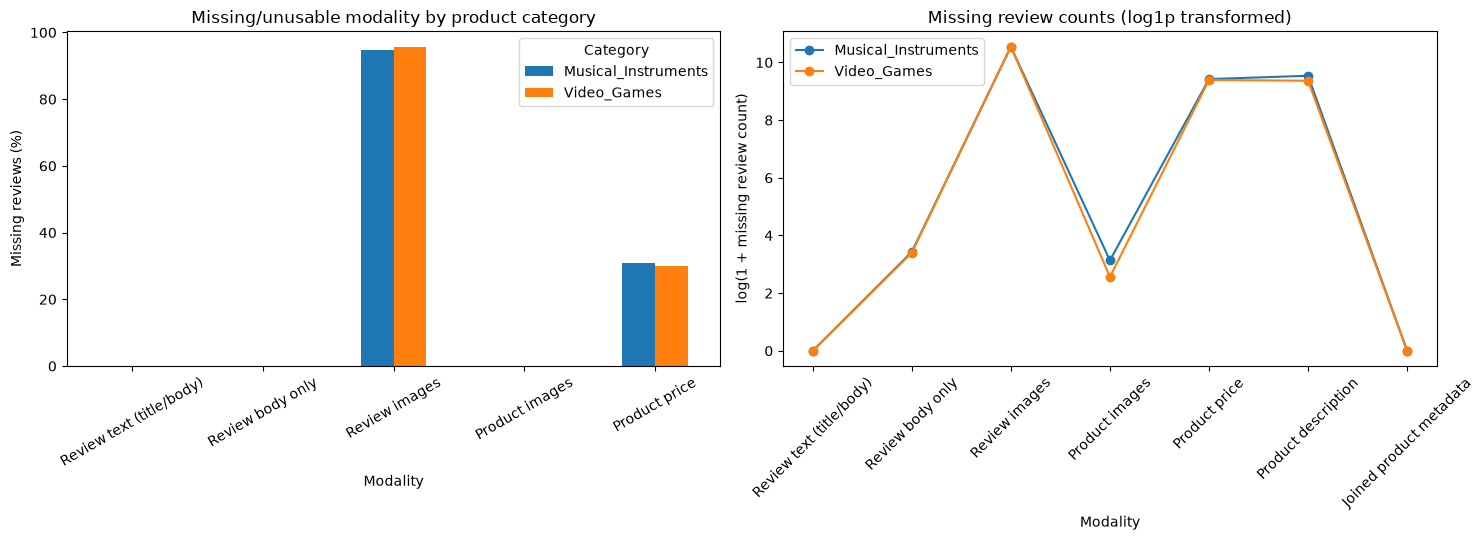

Review text (title/body): No missingness variation; category test not possible. This is not a determination of random missingness.
Review body only: no statistically detectable category difference. This is not a determination of random missingness.
Review images: category-associated in this sample. This is not a determination of random missingness.
Product images: no statistically detectable category difference. This is not a determination of random missingness.
Product price: category-associated in this sample. This is not a determination of random missingness.
Product description: category-associated in this sample. This is not a determination of random missingness.
Joined product metadata: No missingness variation; category test not possible. This is not a determination of random missingness.
P-values are exploratory, unadjusted for multiple comparisons, and do not establish cause or MCAR.


In [11]:
import math

category_availability_fields = [
    ("Review text (title/body)", "review_text_any"),
    ("Review body only", "review_body"),
    ("Review images", "review_photo"),
    ("Product images", "product_photo"),
    ("Product price", "product_price"),
    ("Product description", "product_description"),
    ("Joined product metadata", "joined_product_metadata"),
]

category_missingness_rows = []
for modality, col in category_availability_fields:
    for category in CATEGORIES:
        values = modality_per_review.loc[
            modality_per_review["dataset_category"] == category, col
        ]
        n = len(values)
        missing = int((~values).sum())
        category_missingness_rows.append({
            "modality": modality, "category": category,
            "n_reviews": n, "available_n": n - missing,
            "missing_n": missing, "missing_rate": missing / n if n else np.nan,
        })
category_missingness = pd.DataFrame(category_missingness_rows)
display(category_missingness)

# Exploratory category comparison of two binomial proportions.
# Only use the normal approximation when each expected 2x2 count >= 5.
def missingness_category_comparison(modality):
    subset = category_missingness.loc[category_missingness["modality"] == modality].set_index("category")
    a = subset.loc[CATEGORIES[0]]
    b = subset.loc[CATEGORIES[1]]
    n1, x1 = int(a["n_reviews"]), int(a["missing_n"])
    n2, x2 = int(b["n_reviews"]), int(b["missing_n"])
    rate1, rate2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    expected = [(n1 * pooled), n1 * (1 - pooled), n2 * pooled, n2 * (1 - pooled)]
    if pooled == 0 or pooled == 1:
        p, status = np.nan, "No missingness variation; category test not possible"
    elif min(expected) < 5:
        p, status = np.nan, "Sparse expected counts; report rates descriptively"
    else:
        standard_error = math.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
        z = (rate1 - rate2) / standard_error
        p = math.erfc(abs(z) / math.sqrt(2))
        status = "Exploratory two-sided two-proportion z-test"
    return {
        "modality": modality,
        f"missing_n_{CATEGORIES[0]}": x1,
        f"missing_pct_{CATEGORIES[0]}": 100 * rate1,
        f"missing_n_{CATEGORIES[1]}": x2,
        f"missing_pct_{CATEGORIES[1]}": 100 * rate2,
        "missing_rate_difference_percentage_points_Musical_minus_Video": 100 * (rate1 - rate2),
        "unadjusted_p_value_if_testable": p,
        "test_status": status,
    }

category_missingness_comparison = pd.DataFrame([
    missingness_category_comparison(modality)
    for modality, _ in category_availability_fields
])
display(category_missingness_comparison)

# Category-wise visual comparison of unavailability. No data have been imputed.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
selected = ["Review text (title/body)", "Review body only",
            "Review images", "Product images", "Product price"]
wide = (category_missingness.loc[category_missingness["modality"].isin(selected)]
        .pivot(index="modality", columns="category", values="missing_rate")
        .reindex(selected))
wide.mul(100).plot.bar(ax=axes[0], rot=30)
axes[0].set(title="Missing/unusable modality by product category",
            xlabel="Modality", ylabel="Missing reviews (%)")
axes[0].legend(title="Category")
# Use the actual log1p transform (not a symlog axis); exact counts remain in the table.
for category in CATEGORIES:
    sub = category_missingness[category_missingness["category"] == category]
    axes[1].plot(sub["modality"], np.log1p(sub["missing_n"]), marker="o", label=category)
axes[1].set(title="Missing review counts (log1p transformed)", xlabel="Modality",
            ylabel="log(1 + missing review count)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

for _, row in category_missingness_comparison.iterrows():
    if pd.notna(row["unadjusted_p_value_if_testable"]):
        statement = "category-associated in this sample" if row["unadjusted_p_value_if_testable"] < 0.05 else "no statistically detectable category difference"
    else:
        statement = row["test_status"]
    print(f"{row['modality']}: {statement}. This is not a determination of random missingness.")
print("P-values are exploratory, unadjusted for multiple comparisons, and do not establish cause or MCAR.")


## 5. Univariate Exploratory Data Analysis

### Variables to inspect

- `helpful_vote`: the count target; examine zeros, skewness, median, upper quantiles, and extreme values.
- `rating`: star-rating distribution and imbalance.
- Text length: character count, word count, and sentence count; identify very short and very long reviews.
- Time: publication-year/month distribution and coverage.
- Category and verified-purchase status: categorical frequencies.
- Product price and metadata availability: only where those fields are present.

For the Amazon path, inspect text length, the frequency of very short/long reviews, and unusual character patterns. A Unicode/non-Latin ratio is only a screening statistic; it is not a reliable language detector.


- Histograms below show values **up to the 99th percentile without clipping**; the displayed sample size and excluded tail count are explicitly reported. A large bar at the cutoff therefore does not secretly combine all larger observations.
- After HTML decoding and tag removal, a review that contains only symbols or emojis can have `text_word_count == 0` while `text_present == True`; this is a tokenization limitation, not proof of an empty review.
- We inspect text anomalies **separately for each category**, including blank text, very short/long text, non-ASCII characters, emoji/symbol content, and zero-token but nonempty text. Non-ASCII characters do not reliably identify language.


### HTML-aware text cleaning

The analysis preserves `combined_text` as the unmodified source title/body, then removes HTML markup and decodes entities into `cleaned_text`. All text-length and text-pattern calculations use the cleaned version. The notebook reports what fraction changed and shows raw/cleaned examples by category. A raw word-count of zero for an emoji-only review is not a missing review; the word counter recognizes letters/digits, not all symbols.


,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max,skewness
helpful_vote_num,80000.0,1.160050,15.623138,0.0,0.00,0.000000,0.000000,0.000000,1.000000,2.000000,4.000000,16.000000,3931.000000,202.086629
rating_num,80000.0,4.147275,1.362345,1.0,1.00,1.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,-1.408890
text_char_count,80000.0,293.907575,546.385288,3.0,14.00,22.000000,65.000000,150.000000,316.000000,641.000000,1002.000000,2408.050000,31815.000000,10.887020
text_word_count,80000.0,55.785700,102.175006,0.0,2.00,4.000000,12.000000,28.000000,60.000000,122.100000,191.000000,453.000000,5678.000000,10.295974
text_sentence_count,80000.0,4.185412,5.807767,1.0,1.00,1.000000,1.000000,3.000000,5.000000,8.000000,12.000000,27.000000,255.000000,8.247679
non_ascii_ratio,80000.0,0.001629,0.016890,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.008333,0.027027,0.909091,37.017853
exclamation_count,80000.0,0.580350,1.626561,0.0,0.00,0.000000,0.000000,0.000000,1.000000,2.000000,3.000000,6.000000,114.000000,17.999926
question_count,80000.0,0.058500,0.409975,0.0,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,27.000000,16.046886
uppercase_ratio,80000.0,0.061632,0.077597,0.0,0.00,0.014286,0.028623,0.042735,0.069444,0.117647,0.157895,0.302326,1.000000,7.266104
product_price_num,55649.0,67.777165,122.819565,0.0,4.99,7.990000,16.040000,29.990000,65.000000,159.990000,252.986000,549.000000,4819.000000,8.368743


Helpful-vote zero fraction: 73.46%
Helpful-vote median: 0.0
Helpful-vote mean: 1.16005
Helpful-vote 95th percentile: 4.0
Helpful-vote 99th percentile: 16.0
Helpful-vote maximum: 3931
Reviews with <= 5 words: 9.46%
Reviews with >= 200 words: 4.64%
Helpful-vote histogram: showing 79,205/80,000 observations <= p99=16; 795 in the excluded right tail.
Word-count histogram: showing 79,204/80,000 observations <= p99=453; 796 in the excluded right tail.


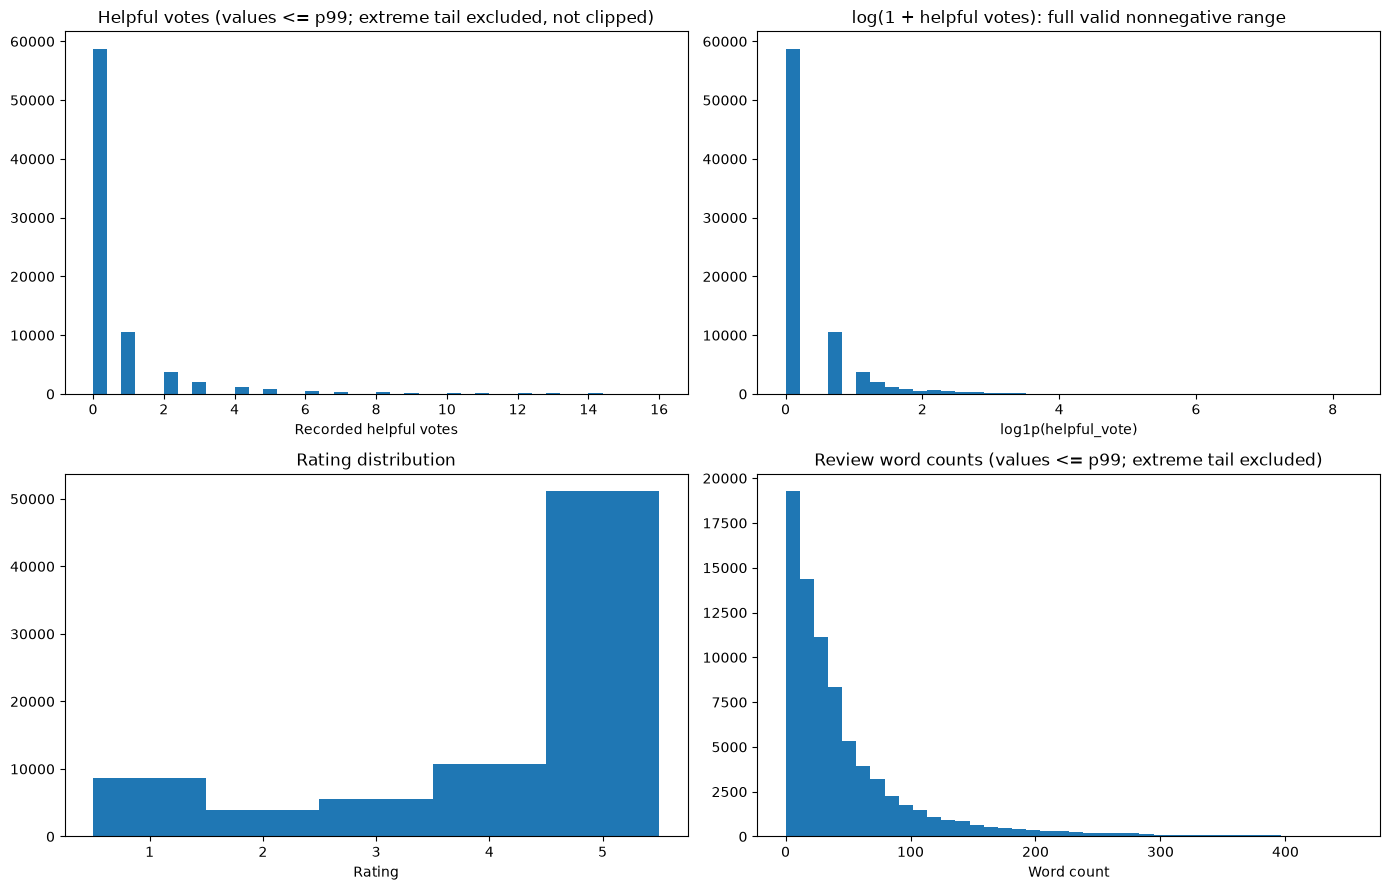

,dataset_category,review_year,review_count
0,Musical_Instruments,2000,1
1,Musical_Instruments,2001,1
2,Musical_Instruments,2002,1
3,Musical_Instruments,2003,1
4,Musical_Instruments,2004,6
5,Musical_Instruments,2005,13
6,Musical_Instruments,2006,17
7,Musical_Instruments,2007,36
8,Musical_Instruments,2008,52
9,Musical_Instruments,2009,98


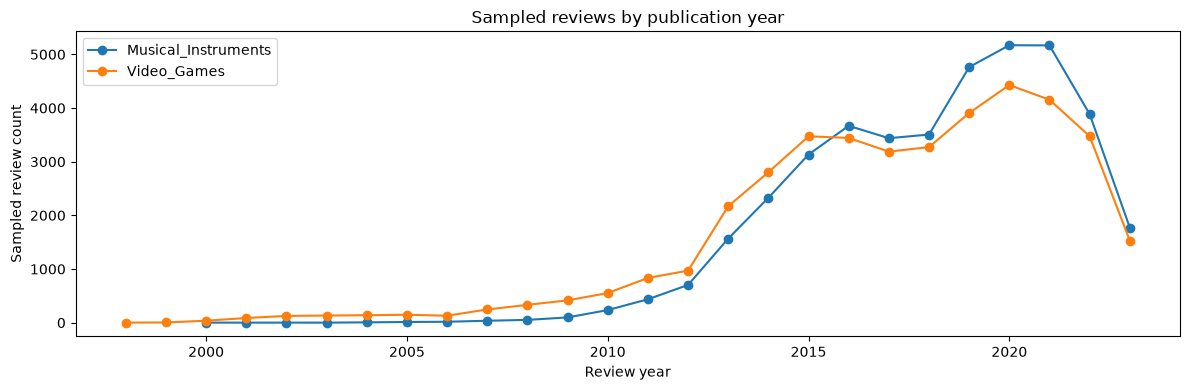

text_present      very_short_text_0_to_5_words          \
                             sum mean                          sum    mean   
dataset_category                                                             
Musical_Instruments        40000  1.0                         3448  0.0862   
Video_Games                40000  1.0                         4116  0.1029   

                    very_long_text_200plus_words            \
                                             sum      mean   
dataset_category                                             
Musical_Instruments                         1307  0.032675   
Video_Games                                 2409  0.060225   

                    nonempty_zero_word_tokens           non_ascii_above_20pct  \
                                          sum      mean                   sum   
dataset_category                                                                
Musical_Instruments                        17  0.000425                    19   
Video_Games                                24  0.000600                    33   

                              emoji_or_symbol_present            
                         mean                     sum      mean  
dataset_category                                                 
Musical_Instruments  0.000475                     419  0.010475  
Video_Games          0.000825                     464  0.011600

,category,anomaly_flag,word_count,non_ascii_ratio,text_preview
0,Musical_Instruments,nonempty_zero_word_tokens,0,0.666667,👏 👏
1,Musical_Instruments,nonempty_zero_word_tokens,0,0.000000,* *
2,Musical_Instruments,nonempty_zero_word_tokens,0,0.666667,👍 👍
3,Musical_Instruments,nonempty_zero_word_tokens,0,0.750000,😊 👍🏼
4,Musical_Instruments,nonempty_zero_word_tokens,0,0.800000,☹☹ ☹☹
5,Musical_Instruments,non_ascii_above_20pct,0,0.666667,👏 👏
6,Musical_Instruments,non_ascii_above_20pct,2,0.352941,Five Stars 👍🏻👍🏻👍🏻
7,Musical_Instruments,non_ascii_above_20pct,0,0.666667,👍 👍
8,Musical_Instruments,non_ascii_above_20pct,0,0.750000,😊 👍🏼
9,Musical_Instruments,non_ascii_above_20pct,0,0.800000,☹☹ ☹☹


Emoji-only text can contain zero regex word tokens despite having real content.
Optional langdetect package not installed: NO language identification was performed. Character and emoji audits above still run.


In [12]:
numeric_columns = [
    c for c in [
        "helpful_vote_num", "rating_num", "text_char_count",
        "text_word_count", "text_sentence_count", "non_ascii_ratio",
        "exclamation_count", "question_count", "uppercase_ratio",
        "product_price_num", "review_images_count", "product_images_count",
    ] if c in analysis_df.columns
]

univariate_summary = analysis_df[numeric_columns].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T
univariate_summary["skewness"] = analysis_df[numeric_columns].skew(numeric_only=True)
display(univariate_summary)

target = analysis_df["helpful_vote_num"].dropna()
if len(target):
    print("Helpful-vote zero fraction:", f"{(target == 0).mean():.2%}")
    print("Helpful-vote median:", target.median())
    print("Helpful-vote mean:", target.mean())
    print("Helpful-vote 95th percentile:", target.quantile(0.95))
    print("Helpful-vote 99th percentile:", target.quantile(0.99))
    print("Helpful-vote maximum:", target.max())

print("Reviews with <= 5 words:", f"{(analysis_df['text_word_count'] <= 5).mean():.2%}")
print("Reviews with >= 200 words:", f"{(analysis_df['text_word_count'] >= 200).mean():.2%}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
if len(target):
    plot_cap = target.quantile(0.99)
    shown_votes = target[target <= plot_cap]
    print(f"Helpful-vote histogram: showing {len(shown_votes):,}/{len(target):,} observations <= p99={plot_cap:g}; "
          f"{len(target)-len(shown_votes):,} in the excluded right tail.")
    axes[0, 0].hist(shown_votes, bins=40)
    axes[0, 0].set_title("Helpful votes (values <= p99; extreme tail excluded, not clipped)")
    axes[0, 0].set_xlabel("Recorded helpful votes")
    safe_votes = target[target >= 0]
    axes[0, 1].hist(np.log1p(safe_votes), bins=40)
    axes[0, 1].set_title("log(1 + helpful votes): full valid nonnegative range")
    axes[0, 1].set_xlabel("log1p(helpful_vote)")

axes[1, 0].hist(analysis_df["rating_num"].dropna(), bins=np.arange(0.5, 6.5, 1))
axes[1, 0].set_title("Rating distribution")
axes[1, 0].set_xlabel("Rating")

word_counts = analysis_df["text_word_count"].dropna()
if len(word_counts):
    word_cap = word_counts.quantile(0.99)
    shown_words = word_counts[word_counts <= word_cap]
    print(f"Word-count histogram: showing {len(shown_words):,}/{len(word_counts):,} observations <= p99={word_cap:g}; "
          f"{len(word_counts)-len(shown_words):,} in the excluded right tail.")
    axes[1, 1].hist(shown_words, bins=40)
    axes[1, 1].set_title("Review word counts (values <= p99; extreme tail excluded)")
    axes[1, 1].set_xlabel("Word count")
plt.tight_layout()
plt.show()

analysis_df["review_year"] = analysis_df["timestamp_dt"].dt.year
analysis_df["review_month"] = analysis_df["timestamp_dt"].dt.tz_localize(None).dt.to_period("M").astype(str)
year_counts = (
    analysis_df.groupby(["dataset_category", "review_year"])
    .size().rename("review_count").reset_index()
)
display(year_counts.head(30))

if analysis_df["review_year"].notna().any():
    plt.figure(figsize=(12, 4))
    for category in CATEGORIES:
        subset = year_counts[year_counts["dataset_category"] == category]
        plt.plot(subset["review_year"], subset["review_count"], marker="o", label=category)
    plt.title("Sampled reviews by publication year")
    plt.xlabel("Review year")
    plt.ylabel("Sampled review count")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Audit unusual text without assuming every non-ASCII character means a foreign language.
emoji_pattern = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
analysis_df["emoji_or_symbol_present"] = analysis_df["cleaned_text"].str.contains(emoji_pattern)
analysis_df["nonempty_zero_word_tokens"] = (
    analysis_df["text_present"] & analysis_df["text_word_count"].eq(0)
)
analysis_df["non_ascii_above_20pct"] = (
    analysis_df["text_present"] & analysis_df["non_ascii_ratio"].gt(0.20)
)
analysis_df["very_short_text_0_to_5_words"] = analysis_df["text_word_count"].le(5)
analysis_df["very_long_text_200plus_words"] = analysis_df["text_word_count"].ge(200)

text_audit_flags = [
    "text_present", "very_short_text_0_to_5_words", "very_long_text_200plus_words",
    "nonempty_zero_word_tokens", "non_ascii_above_20pct", "emoji_or_symbol_present"
]
text_audit = (
    analysis_df.groupby("dataset_category")[text_audit_flags]
    .agg(["sum", "mean"])
)
display(text_audit)

# Show examples *from both categories* and each selected anomaly type.
text_anomaly_rows = []
for category in CATEGORIES:
    cat = analysis_df[analysis_df["dataset_category"] == category]
    for flag in ["nonempty_zero_word_tokens", "non_ascii_above_20pct", "very_long_text_200plus_words"]:
        examples = cat.loc[cat[flag]].head(5)
        for _, row in examples.iterrows():
            text_anomaly_rows.append({
                "category": category, "anomaly_flag": flag,
                "word_count": row["text_word_count"],
                "non_ascii_ratio": row["non_ascii_ratio"],
                "text_preview": str(row["cleaned_text"])[:160]
            })
text_anomaly_examples = pd.DataFrame(text_anomaly_rows, columns=[
    "category", "anomaly_flag", "word_count", "non_ascii_ratio", "text_preview"
])
display(text_anomaly_examples)
print("Emoji-only text can contain zero regex word tokens despite having real content.")

# Optional: use existing langdetect if installed; label it a heuristic, not verified language.
try:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = SEED
    language_rows = []
    for category in CATEGORIES:
        candidates = analysis_df.loc[
            (analysis_df["dataset_category"] == category) &
            (analysis_df["text_present"]) &
            (analysis_df["cleaned_text"].str.count(r"[A-Za-z]") >= 10),
            "cleaned_text"
        ]
        candidates = candidates.sample(n=min(500, len(candidates)), random_state=SEED)
        for value in candidates:
            try:
                lang = detect(value[:5000])
            except Exception:
                lang = "undetermined"
            language_rows.append({"category": category, "detected_language_heuristic": lang})
    language_summary = (
        pd.DataFrame(language_rows)
        .groupby(["category", "detected_language_heuristic"])
        .size().rename("sample_rows").reset_index()
        if language_rows else pd.DataFrame(columns=["category", "detected_language_heuristic", "sample_rows"])
    )
    display(language_summary)
except ImportError:
    language_summary = pd.DataFrame(columns=["category", "detected_language_heuristic", "sample_rows"])
    print("Optional langdetect package not installed: NO language identification was performed. Character and emoji audits above still run.")


### HTML cleaning audit — effect on measured text lengths

The original text is retained unchanged in `combined_text`. The `cleaned_text` field decodes entities like `&ouml;` and strips markup like `<br />` before computing textual features. The audit reports changed/markup/entity rows **for each category**, review body/title coverage, mean word counts before/after, and representative before/after examples. Normalization also collapses whitespace, so `html_cleaning_changed` includes whitespace-only changes; it does not mean every changed review contained HTML. No raw source reviews are overwritten.

In [13]:
# Count raw text words for auditing only. Existing EDA features use cleaned_text.
analysis_df["raw_text_word_count"] = analysis_df["combined_text"].str.findall(r"\b\w+\b").str.len()
analysis_df["word_count_delta"] = analysis_df["text_word_count"] - analysis_df["raw_text_word_count"]

html_cleaning_rows = []
html_example_frames = []
for category in CATEGORIES:
    subset = analysis_df.loc[analysis_df["dataset_category"] == category].copy()
    html_cleaning_rows.append({
        "category": category,
        "n": len(subset),
        "markup_detected_n": int(subset["html_markup_detected"].sum()),
        "entity_detected_n": int(subset["html_entity_detected"].sum()),
        "any_cleaning_changed_n": int(subset["html_cleaning_changed"].sum()),
        "cleaning_changed_pct": 100 * subset["html_cleaning_changed"].mean(),
        "title_available_pct": 100 * subset["text_title_present"].mean(),
        "body_available_pct": 100 * subset["text_body_present"].mean(),
        "combined_text_available_pct": 100 * subset["text_present"].mean(),
        "mean_raw_words": subset["raw_text_word_count"].mean(),
        "mean_cleaned_words": subset["text_word_count"].mean(),
        "mean_delta_words": subset["word_count_delta"].mean(),
        "word_count_changed_n": int(subset["word_count_delta"].ne(0).sum()),
    })
    flagged = subset.loc[
        subset["html_markup_detected"] | subset["html_entity_detected"]
    ].head(6)
    if flagged.empty:
        flagged = subset.loc[subset["html_cleaning_changed"]].head(4)
    if not flagged.empty:
        examples = flagged[[
            "dataset_category", "combined_text", "cleaned_text",
            "raw_text_word_count", "text_word_count",
            "html_markup_detected", "html_entity_detected"
        ]].copy()
        examples["combined_text"] = examples["combined_text"].str.slice(0, 180)
        examples["cleaned_text"] = examples["cleaned_text"].str.slice(0, 180)
        html_example_frames.append(examples)

html_cleaning_audit = pd.DataFrame(html_cleaning_rows)
html_cleaning_examples = (
    pd.concat(html_example_frames, ignore_index=True)
    if html_example_frames else pd.DataFrame(columns=[
        "dataset_category", "combined_text", "cleaned_text",
        "raw_text_word_count", "text_word_count",
        "html_markup_detected", "html_entity_detected"
    ])
)
display(html_cleaning_audit.round(3))
display(html_cleaning_examples)
print("Counts in later charts, correlations and text audits are based on cleaned_text.")

,category,n,markup_detected_n,entity_detected_n,any_cleaning_changed_n,cleaning_changed_pct,title_available_pct,body_available_pct,combined_text_available_pct,mean_raw_words,mean_cleaned_words,mean_delta_words,word_count_changed_n
0,Musical_Instruments,40000,4689,810,11892,29.730,100.0,99.925,100.0,49.510,48.969,-0.541,5197
1,Video_Games,40000,5871,824,10998,27.495,100.0,99.928,100.0,63.581,62.602,-0.978,6276


,dataset_category,combined_text,cleaned_text,raw_text_word_count,text_word_count,html_markup_detected,html_entity_detected
0,Musical_Instruments,"Amazing Kit, Amazing Price I grew up on an ""analogue"" set. A black Pear Export 5 piece. I was hesitant about how an ...","Amazing Kit, Amazing Price I grew up on an ""analogue"" set. A black Pear Export 5 piece. I was hesitant about how an ...",715,687,True,False
1,Musical_Instruments,"New Fav! OMG! Is all I can say.<br />I can't leave it alone, sums it up!<br />Size, price, tone GREAT.<br />As far a...","New Fav! OMG! Is all I can say. I can't leave it alone, sums it up! Size, price, tone GREAT. As far as versatility, ...",39,35,True,False
2,Musical_Instruments,Elastic and stretchable Great product<br />Elastic and can fit a variety of keyboards!!,Elastic and stretchable Great product Elastic and can fit a variety of keyboards!!,14,13,True,False
3,Musical_Instruments,Updated: Amazing low lying fog when used with fog chiller [[VIDEOID:7681f146837eb84c54b613f29f8b5e99]] Update 9/12/2...,Updated: Amazing low lying fog when used with fog chiller [[VIDEOID:7681f146837eb84c54b613f29f8b5e99]] Update 9/12/2...,67,65,True,False
4,Musical_Instruments,"Plus and minus. The guitar is GREAT. The accessories not so much.<br />The guitar tuner (Gearlux), is junk. The ins...","Plus and minus. The guitar is GREAT. The accessories not so much. The guitar tuner (Gearlux), is junk. The instructi...",98,93,True,False
5,Musical_Instruments,Absolutely Masterful - Unbeatable - Period. Wunderbaar und h&ouml;chste !!!!<br /><br />(Wonderful and Supreme)<br ...,Absolutely Masterful - Unbeatable - Period. Wunderbaar und höchste !!!! (Wonderful and Supreme) This product is a ha...,2046,1983,True,True
6,Video_Games,Awesome but need adapter Headphones fit great<br />Great noise cancelation<br />Only con is that you have to buy an ...,Awesome but need adapter Headphones fit great Great noise cancelation Only con is that you have to buy an adapter fo...,39,35,True,False
7,Video_Games,"Overall horrible game. Toxic community, and pretty much one of the worst developed games I’ve ever played. The level...","Overall horrible game. Toxic community, and pretty much one of the worst developed games I’ve ever played. The level...",57,55,True,False
8,Video_Games,Great keyboard after getting replacement Had this keyboard for 2 months and has already starting to malfunction. Cer...,Great keyboard after getting replacement Had this keyboard for 2 months and has already starting to malfunction. Cer...,122,120,True,False
9,Video_Games,Works great! It feels like i have a steam console Works great!<br />It feels like i have a steam console.,Works great! It feels like i have a steam console Works great! It feels like i have a steam console.,21,20,True,False


Counts in later charts, correlations and text audits are based on cleaned_text.


### Text Audit: Length, Very Short/Long Reviews, Unusual Characters, Rating Relationship

**Review text means cleaned title + body.** Length statistics use decoded/HTML-stripped text, not raw markup. The deliberately chosen screening thresholds are **at most five** word tokens for a *very short* review and **at least 200** for a *very long* review. Empty/nonempty text, emoji-only text, non-ASCII characters, and unusual writing systems are distinct concepts.


,dataset_category,n,combined_text_available_rate,title_available_rate,body_available_rate,very_short_0_to_5_n,very_short_0_to_5_rate,very_long_200plus_n,very_long_200plus_rate,nonempty_zero_word_n,higher_non_ascii_rate,emoji_symbol_rate,median_words,p90_words,p99_words
0,Musical_Instruments,40000,1.0,1.0,0.999250,3448,0.0862,1307,0.032675,17,0.000475,0.010475,28.0,110.0,334.00
1,Video_Games,40000,1.0,1.0,0.999275,4116,0.1029,2409,0.060225,24,0.000825,0.011600,29.0,137.0,570.01


,dataset_category,script_screen_heuristic,n_reviews,rate_within_category
0,Musical_Instruments,ascii_latin,39712,0.992800
1,Musical_Instruments,contains_non_latin_letters,5,0.000125
2,Musical_Instruments,latin_with_diacritics,264,0.006600
3,Musical_Instruments,no_alphabetic_letters,19,0.000475
4,Video_Games,ascii_latin,39641,0.991025
5,Video_Games,contains_non_latin_letters,10,0.000250
6,Video_Games,latin_with_diacritics,322,0.008050
7,Video_Games,no_alphabetic_letters,27,0.000675


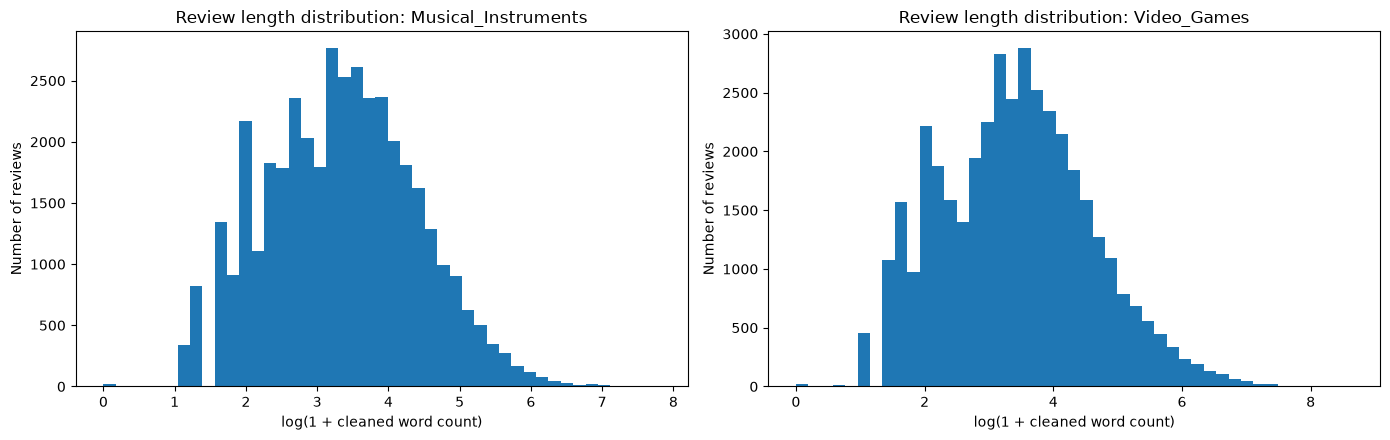

,dataset_category,rating_num,n,median_cleaned_words,mean_cleaned_words,very_short_rate,very_long_rate
0,Musical_Instruments,1.0,3407,34.0,51.648665,0.035515,0.026416
1,Musical_Instruments,2.0,1763,43.0,68.298922,0.022689,0.053885
2,Musical_Instruments,3.0,2649,40.0,65.479804,0.037750,0.052095
3,Musical_Instruments,4.0,5364,37.0,66.801081,0.064318,0.059843
4,Musical_Instruments,5.0,26817,24.0,42.159936,0.105978,0.024723
5,Video_Games,1.0,5233,36.0,60.489394,0.026180,0.045290
6,Video_Games,2.0,2161,53.0,97.803795,0.016659,0.105507
7,Video_Games,3.0,2954,50.0,103.401490,0.032837,0.124577
8,Video_Games,4.0,5316,44.0,98.672874,0.065839,0.118510
9,Video_Games,5.0,24336,22.0,47.099359,0.143655,0.038872


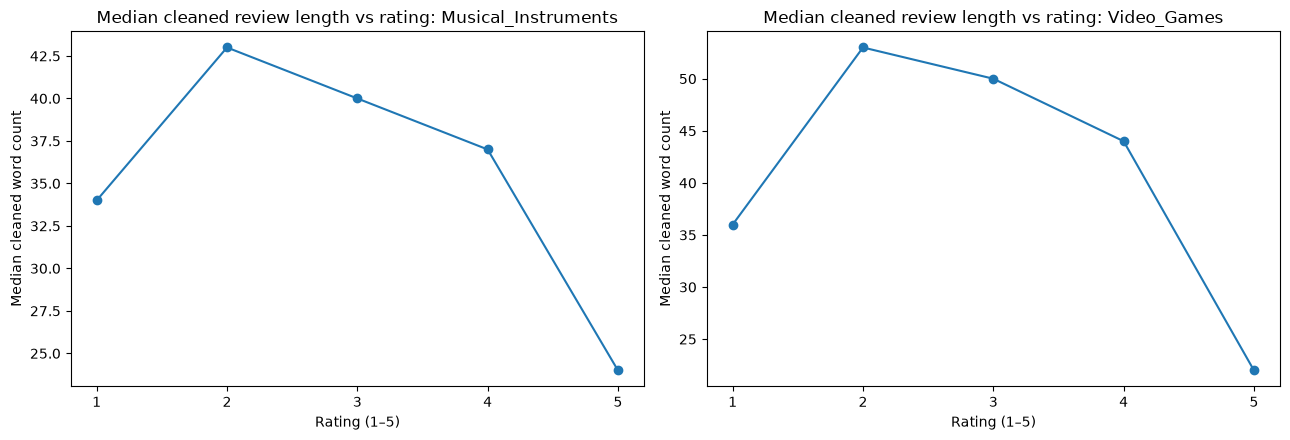

Non-Latin scripts, accents, emoji and non-ASCII characters are not verified language labels.
These are descriptive associations between text characteristics and star ratings.


In [14]:
import unicodedata

def script_screen(text):
    # A rough writing-system screen, NOT language detection.
    if not text:
        return "empty"
    alpha = [ch for ch in text if ch.isalpha()]
    if not alpha:
        return "no_alphabetic_letters"
    non_latin = [ch for ch in alpha if "LATIN" not in unicodedata.name(ch, "")]
    if non_latin:
        return "contains_non_latin_letters"
    accented = [ch for ch in alpha if ord(ch) > 127]
    return "latin_with_diacritics" if accented else "ascii_latin"

analysis_df["script_screen_heuristic"] = analysis_df["cleaned_text"].map(script_screen)
text_audit_detailed = (
    analysis_df.groupby("dataset_category", sort=False)
    .agg(
        n=("cleaned_text", "size"),
        combined_text_available_rate=("text_present", "mean"),
        title_available_rate=("text_title_present", "mean"),
        body_available_rate=("text_body_present", "mean"),
        very_short_0_to_5_n=("very_short_text_0_to_5_words", "sum"),
        very_short_0_to_5_rate=("very_short_text_0_to_5_words", "mean"),
        very_long_200plus_n=("very_long_text_200plus_words", "sum"),
        very_long_200plus_rate=("very_long_text_200plus_words", "mean"),
        nonempty_zero_word_n=("nonempty_zero_word_tokens", "sum"),
        higher_non_ascii_rate=("non_ascii_above_20pct", "mean"),
        emoji_symbol_rate=("emoji_or_symbol_present", "mean"),
        median_words=("text_word_count", "median"),
        p90_words=("text_word_count", lambda x: x.quantile(0.90)),
        p99_words=("text_word_count", lambda x: x.quantile(0.99)),
    ).reset_index()
)
display(text_audit_detailed)

script_audit = (analysis_df.groupby(["dataset_category", "script_screen_heuristic"])
                .size().rename("n_reviews").reset_index())
script_audit["rate_within_category"] = script_audit["n_reviews"] / script_audit.groupby("dataset_category")["n_reviews"].transform("sum")
display(script_audit)

# Per-category distributions: full log1p word lengths retain the long tail.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, category in zip(axes, CATEGORIES):
    vals = analysis_df.loc[analysis_df["dataset_category"] == category, "text_word_count"]
    ax.hist(np.log1p(vals.dropna()), bins=45)
    ax.set(title=f"Review length distribution: {category}",
           xlabel="log(1 + cleaned word count)", ylabel="Number of reviews")
plt.tight_layout()
plt.show()

rating_text_audit = (
    analysis_df.loc[analysis_df["rating_num"].between(1, 5)]
    .groupby(["dataset_category", "rating_num"])
    .agg(n=("text_word_count", "size"),
         median_cleaned_words=("text_word_count", "median"),
         mean_cleaned_words=("text_word_count", "mean"),
         very_short_rate=("very_short_text_0_to_5_words", "mean"),
         very_long_rate=("very_long_text_200plus_words", "mean"))
    .reset_index()
)
display(rating_text_audit)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, category in zip(axes, CATEGORIES):
    part = rating_text_audit[rating_text_audit["dataset_category"] == category]
    ax.plot(part["rating_num"], part["median_cleaned_words"], marker="o")
    ax.set(title=f"Median cleaned review length vs rating: {category}",
           xlabel="Rating (1–5)", ylabel="Median cleaned word count")
    ax.set_xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()
print("Non-Latin scripts, accents, emoji and non-ASCII characters are not verified language labels.")
print("These are descriptive associations between text characteristics and star ratings.")


## 6. Multivariate Exploratory Data Analysis


### Required relationships for this project

1. Helpful-vote count versus rating.
2. Helpful-vote count versus review text length and basic textual characteristics.
3. Helpful-vote count versus verified-purchase status.
4. Helpful-vote count versus publication time.
5. Helpful-vote count versus product metadata such as price or product rating, where available.
6. Helpful-vote count versus reviewer/product activity within the sampled data.
7. Differences between `Musical_Instruments` and `Video_Games`.

**Important:** sampled reviewer/product activity counts below are descriptive summaries of this sample. They are not valid predictive features as currently calculated, because they use the whole sample and may include records that would not yet have existed at the time of a review. Predictive activity features must be recomputed using training-only, past-only information.


### Additional sensitivity and stratified checks

The notebook also compares category means with and without the single most-voted review, after capping counts at the category-specific 99th percentile, and after trimming observations above that percentile. These are **sensitivity checks**, not automatic cleaning rules. It additionally examines rating and cleaned review length within publication periods and within rating-period subgroups. These are observational subgroup analyses; coarse year bands cannot eliminate all confounding. Small groups are reported but not used to draw strong conclusions.


,reviews,target_non_missing,helpful_vote_mean,helpful_vote_median,helpful_vote_p90,zero_vote_rate,median_rating,median_word_count,median_sampled_user_activity,median_sampled_product_activity
dataset_category,,,,,,,,,,
Musical_Instruments,40000,40000,1.088375,0.0,2.0,0.721075,5.0,28.0,1.0,2.0
Video_Games,40000,40000,1.231725,0.0,2.0,0.748175,5.0,29.0,1.0,4.0


,dataset_category,rating_num,count,median,mean,nonzero_vote_rate,mean_log1p_votes
0,Musical_Instruments,1.0,3407,0.0,1.302025,0.390960,0.457259
1,Musical_Instruments,2.0,1763,0.0,1.304027,0.357913,0.409671
2,Musical_Instruments,3.0,2649,0.0,1.172518,0.338241,0.402369
3,Musical_Instruments,4.0,5364,0.0,1.343214,0.318046,0.381969
4,Musical_Instruments,5.0,26817,0.0,0.987769,0.245814,0.291133
5,Video_Games,1.0,5233,0.0,1.941143,0.392127,0.510484
6,Video_Games,2.0,2161,0.0,1.442851,0.342434,0.438767
7,Video_Games,3.0,2954,0.0,1.512187,0.320582,0.396867
8,Video_Games,4.0,5316,0.0,1.349511,0.288939,0.355033
9,Video_Games,5.0,24336,0.0,1.000657,0.197156,0.226452


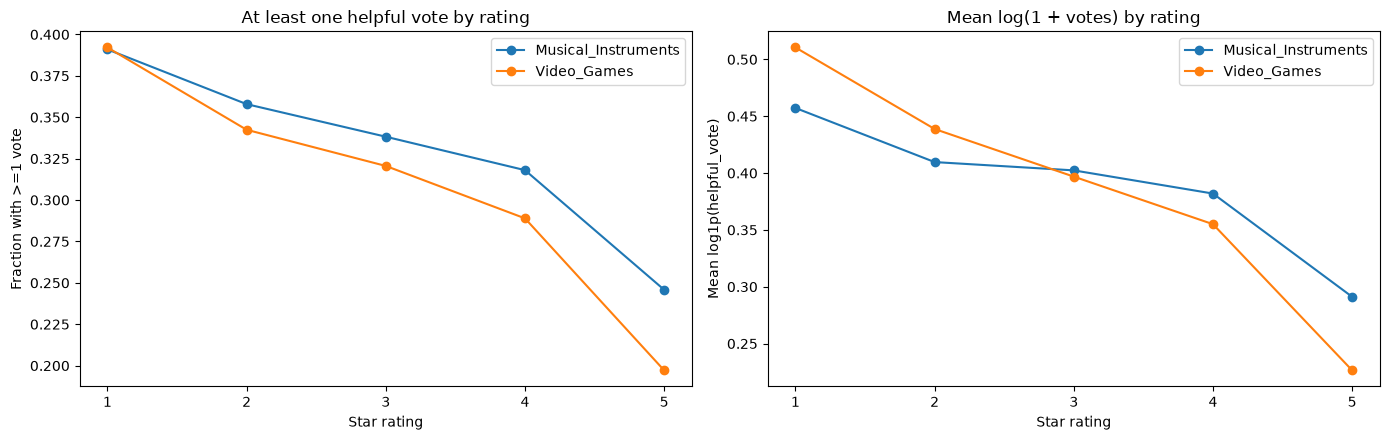

Do not interpret differences as the causal effect of a star rating.


,dataset_category,rating_num,count,median,mean
0,Musical_Instruments,1.0,3407,34.0,51.648665
1,Musical_Instruments,2.0,1763,43.0,68.298922
2,Musical_Instruments,3.0,2649,40.0,65.479804
3,Musical_Instruments,4.0,5364,37.0,66.801081
4,Musical_Instruments,5.0,26817,24.0,42.159936
5,Video_Games,1.0,5233,36.0,60.489394
6,Video_Games,2.0,2161,53.0,97.803795
7,Video_Games,3.0,2954,50.0,103.401490
8,Video_Games,4.0,5316,44.0,98.672874
9,Video_Games,5.0,24336,22.0,47.099359


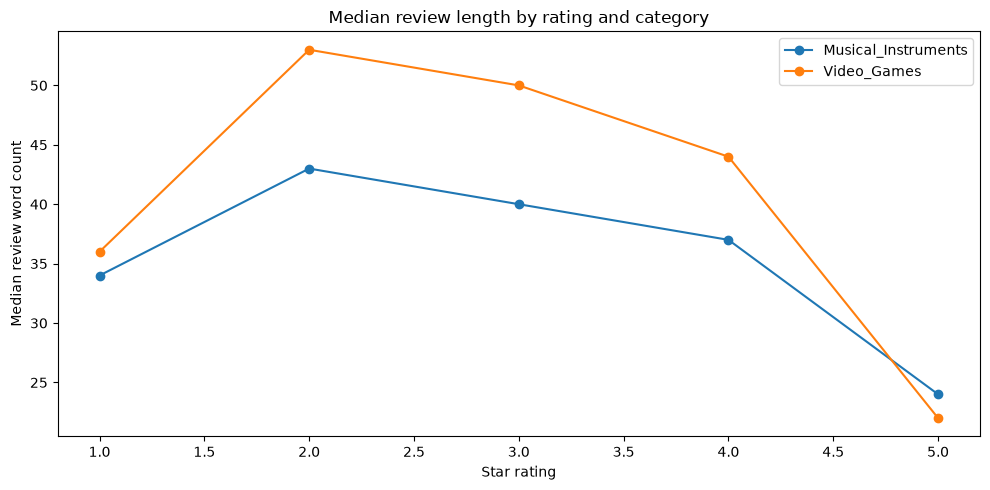

,dataset_category,verified_purchase_clean,count,median,mean
0,Musical_Instruments,False,3219,0.0,1.775396
1,Musical_Instruments,True,36781,0.0,1.028248
2,Video_Games,False,5653,0.0,3.077835
3,Video_Games,True,34347,0.0,0.927883


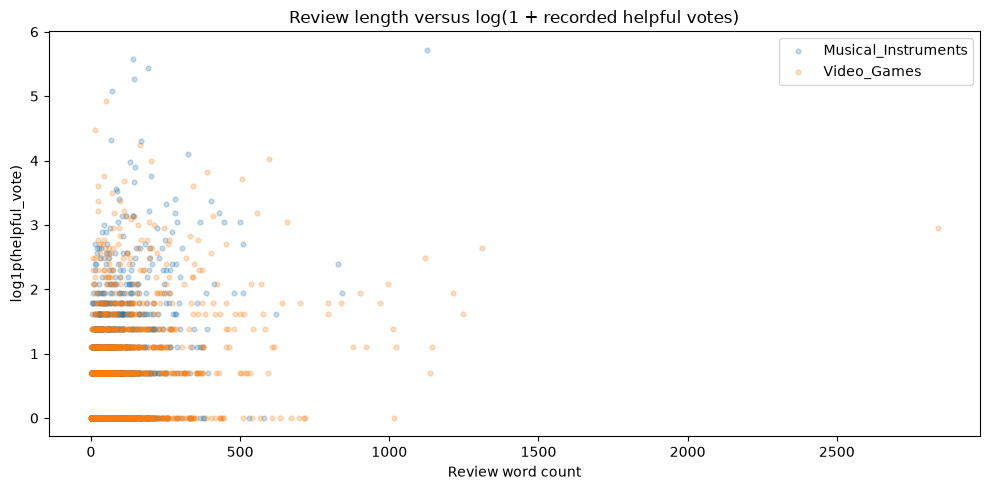

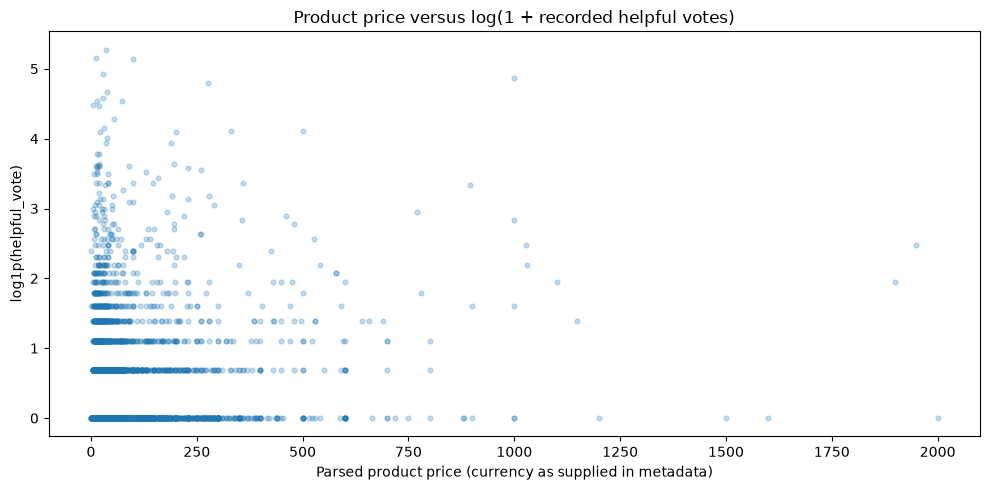

,spearman_helpful_vs_sampled_user_activity,spearman_helpful_vs_sampled_product_activity
dataset_category,,
Musical_Instruments,0.028048,-0.149407
Video_Games,0.036920,-0.110114


,dataset_category,review_year,review_count,nonzero_vote_rate,mean_log1p_votes,mean_votes,median_votes
0,Musical_Instruments,2000,1,1.000000,1.386294,3.000000,3.0
1,Musical_Instruments,2001,1,1.000000,1.386294,3.000000,3.0
2,Musical_Instruments,2002,1,1.000000,2.944439,18.000000,18.0
3,Musical_Instruments,2003,1,1.000000,2.397895,10.000000,10.0
4,Musical_Instruments,2004,6,1.000000,2.299693,11.666667,9.0
5,Musical_Instruments,2005,13,1.000000,2.087065,9.384615,9.0
6,Musical_Instruments,2006,17,1.000000,2.176880,14.764706,7.0
7,Musical_Instruments,2007,36,0.805556,1.460096,8.388889,2.0
8,Musical_Instruments,2008,52,0.884615,1.362672,4.923077,3.0
9,Musical_Instruments,2009,98,0.785714,1.237426,6.112245,2.0


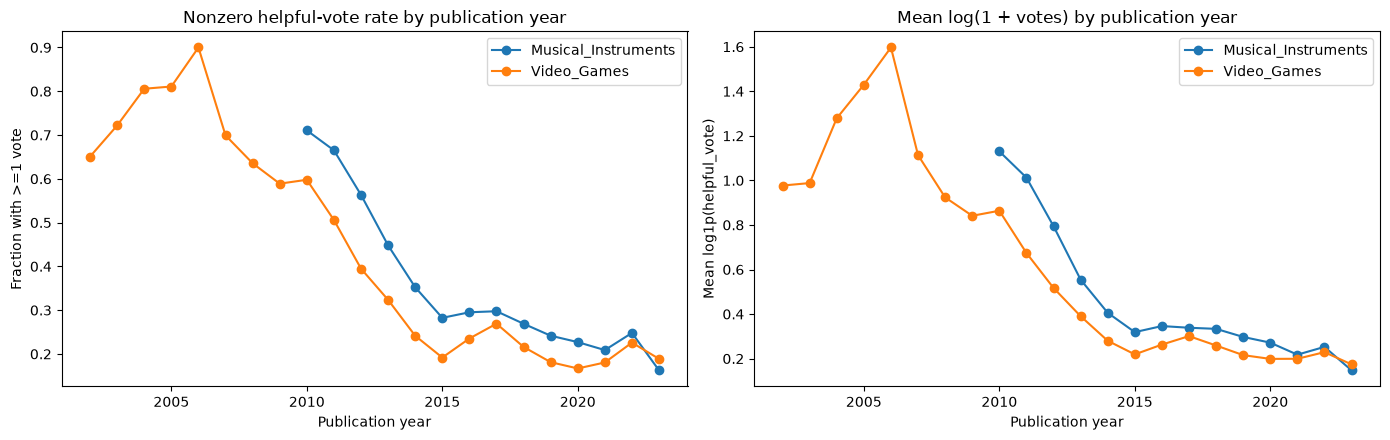

Only year/category groups with >= 100 sampled reviews are drawn; all groups remain in the table.
Historical counts reflect different exposure durations, not votes earned within a common time horizon.


,helpful_vote_num,rating_num,text_word_count,text_char_count,text_sentence_count,non_ascii_ratio,product_price_num,sampled_user_review_count,sampled_product_review_count
helpful_vote_num,1.00,-0.14,0.39,0.39,0.36,0.00,0.13,0.03,-0.13
rating_num,-0.14,1.00,-0.23,-0.22,-0.15,-0.06,-0.00,0.01,0.04
text_word_count,0.39,-0.23,1.00,1.00,0.85,0.08,0.14,0.05,-0.06
text_char_count,0.39,-0.22,1.00,1.00,0.85,0.07,0.14,0.05,-0.06
text_sentence_count,0.36,-0.15,0.85,0.85,1.00,0.05,0.13,0.05,-0.05
non_ascii_ratio,0.00,-0.06,0.08,0.07,0.05,1.00,0.03,-0.02,-0.01
product_price_num,0.13,-0.00,0.14,0.14,0.13,0.03,1.00,-0.01,-0.00
sampled_user_review_count,0.03,0.01,0.05,0.05,0.05,-0.02,-0.01,1.00,-0.04
sampled_product_review_count,-0.13,0.04,-0.06,-0.06,-0.05,-0.01,-0.00,-0.04,1.00


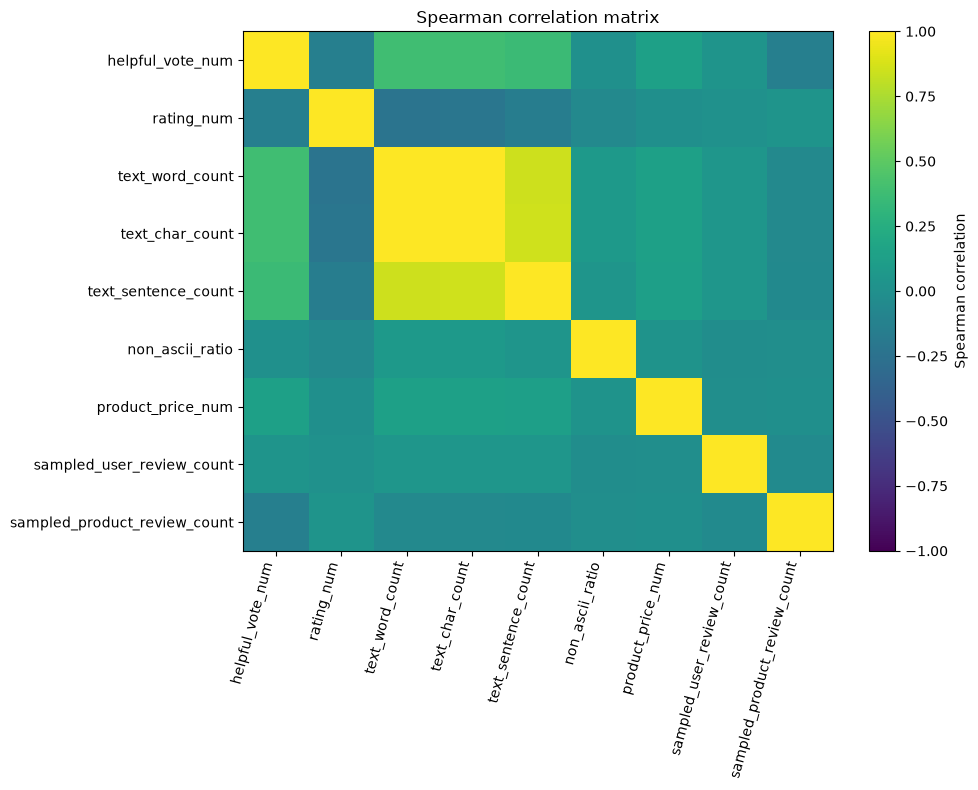

Correlations and subgroup differences are descriptive, not causal.


In [15]:
if "user_id" in analysis_df.columns:
    analysis_df["sampled_user_review_count"] = (
        analysis_df.groupby("user_id")["user_id"].transform("size")
    )
else:
    analysis_df["sampled_user_review_count"] = np.nan

analysis_df["sampled_product_review_count"] = (
    analysis_df.groupby(["dataset_category", "_join_key"])["_join_key"].transform("size")
)

category_eda = (
    analysis_df.groupby("dataset_category")
    .agg(
        reviews=("helpful_vote_num", "size"),
        target_non_missing=("helpful_vote_num", "count"),
        helpful_vote_mean=("helpful_vote_num", "mean"),
        helpful_vote_median=("helpful_vote_num", "median"),
        helpful_vote_p90=("helpful_vote_num", lambda x: x.quantile(0.90)),
        zero_vote_rate=("helpful_vote_num", lambda x: (x.dropna() == 0).mean()),
        median_rating=("rating_num", "median"),
        median_word_count=("text_word_count", "median"),
        median_sampled_user_activity=("sampled_user_review_count", "median"),
        median_sampled_product_activity=("sampled_product_review_count", "median"),
    )
)
display(category_eda)

# Zero-heavy helpful-vote counts make a median-only graph flat and uninformative.
valid_rating_rows = analysis_df.loc[
    analysis_df["rating_num"].notna() & analysis_df["helpful_vote_num"].ge(0)
].copy()
valid_rating_rows["has_votes"] = valid_rating_rows["helpful_vote_num"].gt(0)
valid_rating_rows["log1p_votes"] = np.log1p(valid_rating_rows["helpful_vote_num"])
rating_target = (
    valid_rating_rows.groupby(["dataset_category", "rating_num"], observed=True)
    .agg(
        count=("helpful_vote_num", "size"),
        median=("helpful_vote_num", "median"),
        mean=("helpful_vote_num", "mean"),
        nonzero_vote_rate=("has_votes", "mean"),
        mean_log1p_votes=("log1p_votes", "mean"),
    ).reset_index()
)
display(rating_target)

if not rating_target.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for category in CATEGORIES:
        subset = rating_target[rating_target["dataset_category"] == category]
        axes[0].plot(subset["rating_num"], subset["nonzero_vote_rate"], marker="o", label=category)
        axes[1].plot(subset["rating_num"], subset["mean_log1p_votes"], marker="o", label=category)
    axes[0].set(title="At least one helpful vote by rating", xlabel="Star rating", ylabel="Fraction with >=1 vote")
    axes[1].set(title="Mean log(1 + votes) by rating", xlabel="Star rating", ylabel="Mean log1p(helpful_vote)")
    for ax in axes:
        ax.set_xticks([1, 2, 3, 4, 5])
        ax.legend()
    plt.tight_layout()
    plt.show()
print("Do not interpret differences as the causal effect of a star rating.")

# Initial text–rating relationship required for the Amazon path.
text_rating = (
    analysis_df.dropna(subset=["rating_num"])
    .groupby(["dataset_category", "rating_num"])["text_word_count"]
    .agg(["count", "median", "mean"]).reset_index()
)
display(text_rating)

if not text_rating.empty:
    plt.figure(figsize=(10, 5))
    for category in CATEGORIES:
        subset = text_rating[text_rating["dataset_category"] == category]
        plt.plot(subset["rating_num"], subset["median"], marker="o", label=category)
    plt.title("Median review length by rating and category")
    plt.xlabel("Star rating")
    plt.ylabel("Median review word count")
    plt.legend()
    plt.tight_layout()
    plt.show()

verified_target = (
    analysis_df.dropna(subset=["helpful_vote_num", "verified_purchase_clean"])
    .groupby(["dataset_category", "verified_purchase_clean"])["helpful_vote_num"]
    .agg(["count", "median", "mean"]).reset_index()
)
display(verified_target)

plot_df = analysis_df.dropna(subset=["text_word_count", "helpful_vote_num"]).copy()
if len(plot_df):
    plot_df = plot_df.sample(n=min(8000, len(plot_df)), random_state=SEED)
    plt.figure(figsize=(10, 5))
    for category in CATEGORIES:
        subset = plot_df[plot_df["dataset_category"] == category]
        plt.scatter(
            subset["text_word_count"], np.log1p(subset["helpful_vote_num"]),
            alpha=0.25, s=12, label=category
        )
    plt.title("Review length versus log(1 + recorded helpful votes)")
    plt.xlabel("Review word count")
    plt.ylabel("log1p(helpful_vote)")
    plt.legend()
    plt.tight_layout()
    plt.show()

price_plot = analysis_df.dropna(subset=["product_price_num", "helpful_vote_num"]).copy()
if len(price_plot):
    price_plot = price_plot.sample(n=min(6000, len(price_plot)), random_state=SEED)
    plt.figure(figsize=(10, 5))
    plt.scatter(
        price_plot["product_price_num"], np.log1p(price_plot["helpful_vote_num"]),
        alpha=0.25, s=12
    )
    plt.title("Product price versus log(1 + recorded helpful votes)")
    plt.xlabel("Parsed product price (currency as supplied in metadata)")
    plt.ylabel("log1p(helpful_vote)")
    plt.tight_layout()
    plt.show()
else:
    print("No usable product-price/target pairs were found in the joined sample.")

activity_rows = []
for category, group in analysis_df.groupby("dataset_category", sort=False):
    row = {"dataset_category": category}
    for col, label in [
        ("sampled_user_review_count", "spearman_helpful_vs_sampled_user_activity"),
        ("sampled_product_review_count", "spearman_helpful_vs_sampled_product_activity"),
    ]:
        pair = group[["helpful_vote_num", col]].dropna()
        row[label] = (
            pair["helpful_vote_num"].corr(pair[col], method="spearman")
            if len(pair) > 2 and pair["helpful_vote_num"].nunique() > 1 and pair[col].nunique() > 1
            else np.nan
        )
    activity_rows.append(row)
activity_summary = pd.DataFrame(activity_rows).set_index("dataset_category")
display(activity_summary)

# Helpful votes versus review publication time (not just a histogram of review counts).
valid_year_rows = analysis_df.loc[
    analysis_df["review_year"].notna() & analysis_df["helpful_vote_num"].ge(0)
].copy()
valid_year_rows["has_votes"] = valid_year_rows["helpful_vote_num"].gt(0)
valid_year_rows["log1p_votes"] = np.log1p(valid_year_rows["helpful_vote_num"])
helpful_by_year = (
    valid_year_rows.groupby(["dataset_category", "review_year"], observed=True)
    .agg(
        review_count=("helpful_vote_num", "size"),
        nonzero_vote_rate=("has_votes", "mean"),
        mean_log1p_votes=("log1p_votes", "mean"),
        mean_votes=("helpful_vote_num", "mean"),
        median_votes=("helpful_vote_num", "median"),
    ).reset_index()
)
display(helpful_by_year)
MIN_YEAR_GROUP_SIZE = 100
helpful_by_year_plot = helpful_by_year.loc[
    helpful_by_year["review_count"] >= MIN_YEAR_GROUP_SIZE
]
if not helpful_by_year_plot.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for category in CATEGORIES:
        part = helpful_by_year_plot.loc[helpful_by_year_plot["dataset_category"] == category]
        if part.empty:
            continue
        axes[0].plot(part["review_year"], part["nonzero_vote_rate"], marker="o", label=category)
        axes[1].plot(part["review_year"], part["mean_log1p_votes"], marker="o", label=category)
    axes[0].set(title="Nonzero helpful-vote rate by publication year", xlabel="Publication year", ylabel="Fraction with >=1 vote")
    axes[1].set(title="Mean log(1 + votes) by publication year", xlabel="Publication year", ylabel="Mean log1p(helpful_vote)")
    for ax in axes:
        ax.legend()
    plt.tight_layout()
    plt.show()
print(f"Only year/category groups with >= {MIN_YEAR_GROUP_SIZE} sampled reviews are drawn; all groups remain in the table.")
print("Historical counts reflect different exposure durations, not votes earned within a common time horizon.")

correlation_columns = [
    c for c in [
        "helpful_vote_num", "rating_num", "text_word_count",
        "text_char_count", "text_sentence_count", "non_ascii_ratio",
        "product_price_num", "sampled_user_review_count",
        "sampled_product_review_count",
    ] if c in analysis_df.columns
]
corr = analysis_df[correlation_columns].corr(method="spearman")
display(corr.style.format("{:.2f}"))

if not corr.empty:
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(corr.values, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=75, ha="right")
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Spearman correlation matrix")
    fig.colorbar(image, ax=ax, label="Spearman correlation")
    plt.tight_layout()
    plt.show()

print("Correlations and subgroup differences are descriptive, not causal.")


### Sensitivity of category averages to unusually high helpful-vote counts

- **Extreme helpful-vote counts:** I will retain extreme vote counts by default rather than automatically removing them. For each category, I will compare the ordinary arithmetic mean, the leave-one-maximum-out mean, the mean after capping values at the category-specific 99th percentile, and the mean calculated using only observations at or below that threshold.
- **Interpretation of alternative means:** I will treat these calculations as sensitivity analyses that answer different statistical questions, not as alternative versions of cleaned ground truth.
- **Robust descriptive statistics:** I will also examine the raw median, nonzero-vote rate, and mean `log1p` of helpful votes to provide additional context that is less sensitive to extreme values.
- **Influence of the highest-vote review:** I will measure the highest-vote review's contribution to the category's total votes and quantify how excluding that single review changes the arithmetic mean.

,category,n,raw_mean_votes,mean_without_one_max,mean_with_top_tail_capped_q99,mean_after_removing_above_q99,removed_n_above_q99,q99_cutoff,largest_vote_count,largest_review_share_of_all_votes_pct,single_max_effect_on_mean,median_votes,nonzero_vote_rate,mean_log1p_votes
0,Musical_Instruments,40000,1.0884,1.0799,0.8454,0.7039,370,16.0,342.0,0.7856,0.0085,0.0,0.2789,0.3301
1,Video_Games,40000,1.2317,1.1335,0.8158,0.6528,399,17.0,3931.0,7.9786,0.0982,0.0,0.2518,0.3048


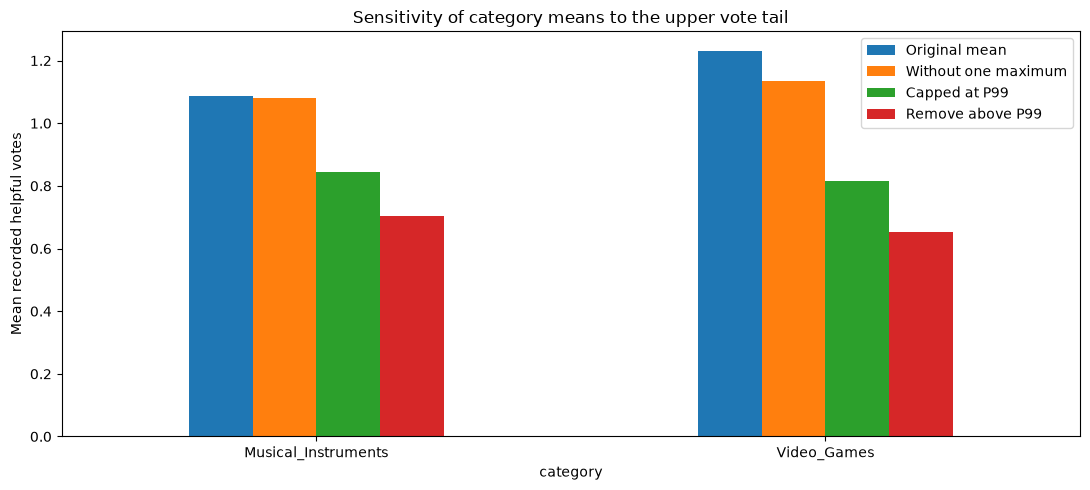

Outlier sensitivity is descriptive only; no reviews have been deleted from analysis_df.


In [16]:
sensitivity_rows = []
for category in CATEGORIES:
    votes = pd.to_numeric(
        analysis_df.loc[analysis_df["dataset_category"] == category, "helpful_vote_num"],
        errors="coerce"
    ).dropna()
    votes = votes.loc[votes >= 0]
    if votes.empty:
        continue
    q99 = votes.quantile(0.99)
    max_vote = votes.max()
    # Remove exactly ONE maximum (not all rows tied for maximum).
    without_max = votes.drop(index=votes.idxmax())
    within_q99 = votes.loc[votes <= q99]
    raw_mean = float(votes.mean())
    sensitivity_rows.append({
        "category": category,
        "n": len(votes),
        "raw_mean_votes": raw_mean,
        "mean_without_one_max": float(without_max.mean()) if len(without_max) else np.nan,
        "mean_with_top_tail_capped_q99": float(votes.clip(upper=q99).mean()),
        "mean_after_removing_above_q99": float(within_q99.mean()),
        "removed_n_above_q99": int((votes > q99).sum()),
        "q99_cutoff": float(q99),
        "largest_vote_count": float(max_vote),
        "largest_review_share_of_all_votes_pct": (
            100 * max_vote / votes.sum() if votes.sum() > 0 else np.nan
        ),
        "single_max_effect_on_mean": (
            raw_mean - without_max.mean() if len(without_max) else np.nan
        ),
        "median_votes": float(votes.median()),
        "nonzero_vote_rate": float((votes > 0).mean()),
        "mean_log1p_votes": float(np.log1p(votes).mean()),
    })

category_sensitivity = pd.DataFrame(sensitivity_rows)
display(category_sensitivity.round(4))

if not category_sensitivity.empty:
    view_cols = {
        "raw_mean_votes": "Original mean",
        "mean_without_one_max": "Without one maximum",
        "mean_with_top_tail_capped_q99": "Capped at P99",
        "mean_after_removing_above_q99": "Remove above P99"
    }
    ax = (category_sensitivity.set_index("category")
          [list(view_cols)].rename(columns=view_cols)
          .plot(kind="bar", figsize=(11, 5), rot=0))
    ax.set_ylabel("Mean recorded helpful votes")
    ax.set_title("Sensitivity of category means to the upper vote tail")
    plt.tight_layout()
    plt.show()
print("Outlier sensitivity is descriptive only; no reviews have been deleted from analysis_df.")

### Rating and review-length associations within publication periods

The unadjusted rating/length associations can partly reflect review age. The following analyses separate publication time into fixed exploratory bands (**≤2009, 2010–2014, 2015–2019, and ≥2020**) and keep the two categories separate. They compute: (1) nonzero-vote rates by rating and time period; (2) within-period Spearman correlations for rating and cleaned word count; and (3) word-count–vote correlations **within both a publication period and a specific star rating**, which controls these two dimensions descriptively. Counts below 100 are still shown but omitted from plots and correlations. Spearman values are associations, not causal effects. Because vote timestamps and equal exposure windows are unavailable, these comparisons cannot fully remove age/exposure bias.

,dataset_category,publication_period,rating_num,n,nonzero_vote_rate,mean_log1p_votes,median_word_count,sufficient_n_for_plot
0,Musical_Instruments,Through 2009,1.0,15,0.866667,1.455145,102.0,False
1,Musical_Instruments,Through 2009,2.0,10,0.900000,1.472712,63.5,False
2,Musical_Instruments,Through 2009,3.0,21,0.904762,1.723677,118.0,False
3,Musical_Instruments,Through 2009,4.0,52,0.903846,1.558265,96.0,False
4,Musical_Instruments,Through 2009,5.0,128,0.812500,1.382506,81.5,True
5,Musical_Instruments,2010–2014,1.0,309,0.644013,0.833247,61.0,True
6,Musical_Instruments,2010–2014,2.0,242,0.553719,0.737771,60.0,True
7,Musical_Instruments,2010–2014,3.0,400,0.495000,0.681462,55.0,True
8,Musical_Instruments,2010–2014,4.0,1032,0.444767,0.569118,53.0,True
9,Musical_Instruments,2010–2014,5.0,3285,0.421613,0.542794,39.0,True


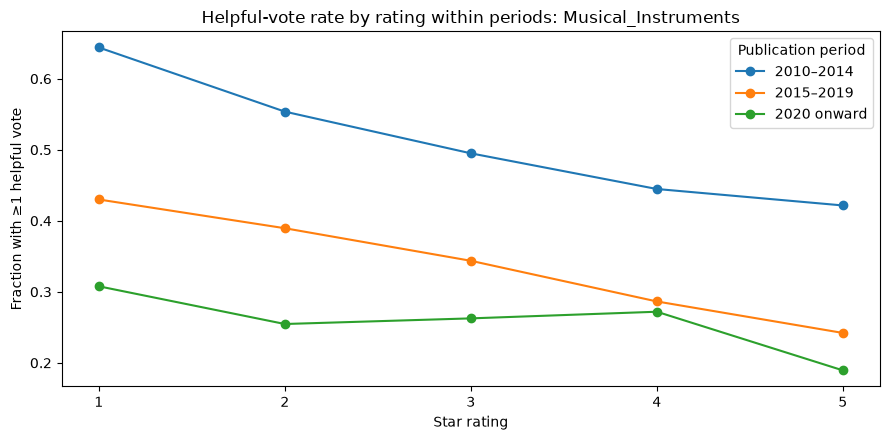

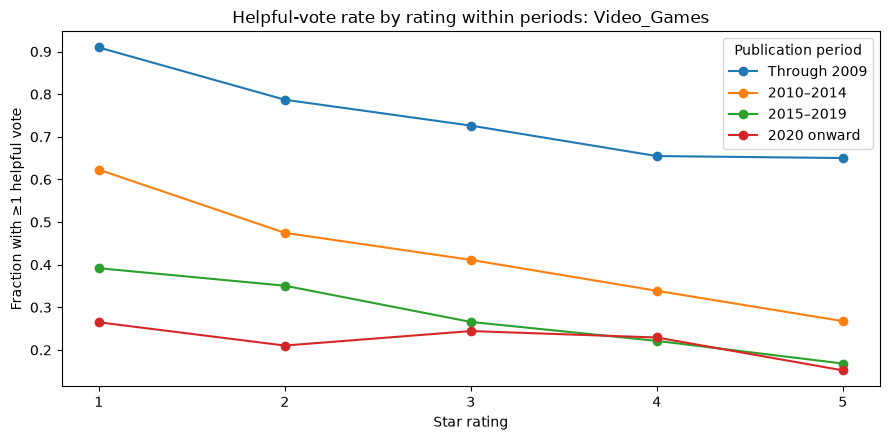

,category,publication_period,n,spearman_rating_vs_votes,spearman_cleaned_words_vs_votes,nonzero_vote_rate
0,Musical_Instruments,Through 2009,226,-0.100,0.365,0.850
1,Musical_Instruments,2010–2014,5268,-0.094,0.440,0.451
2,Musical_Instruments,2015–2019,18509,-0.122,0.406,0.275
3,Musical_Instruments,2020 onward,15997,-0.101,0.313,0.219
4,Video_Games,Through 2009,1799,-0.195,0.399,0.693
5,Video_Games,2010–2014,7329,-0.238,0.417,0.343
6,Video_Games,2015–2019,17283,-0.186,0.335,0.217
7,Video_Games,2020 onward,13589,-0.116,0.268,0.189


,category,publication_period,rating,n,spearman_cleaned_words_vs_votes,nonzero_vote_rate,median_word_count
0,Musical_Instruments,Through 2009,1.0,15,NaN,0.867,102.0
1,Musical_Instruments,Through 2009,2.0,10,NaN,0.900,63.5
2,Musical_Instruments,Through 2009,3.0,21,NaN,0.905,118.0
3,Musical_Instruments,Through 2009,4.0,52,NaN,0.904,96.0
4,Musical_Instruments,Through 2009,5.0,128,0.468,0.812,81.5
5,Musical_Instruments,2010–2014,1.0,309,0.314,0.644,61.0
6,Musical_Instruments,2010–2014,2.0,242,0.445,0.554,60.0
7,Musical_Instruments,2010–2014,3.0,400,0.520,0.495,55.0
8,Musical_Instruments,2010–2014,4.0,1032,0.475,0.445,53.0
9,Musical_Instruments,2010–2014,5.0,3285,0.420,0.422,39.0


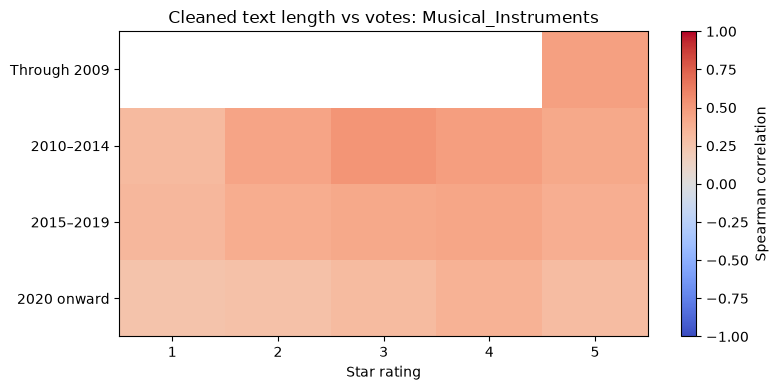

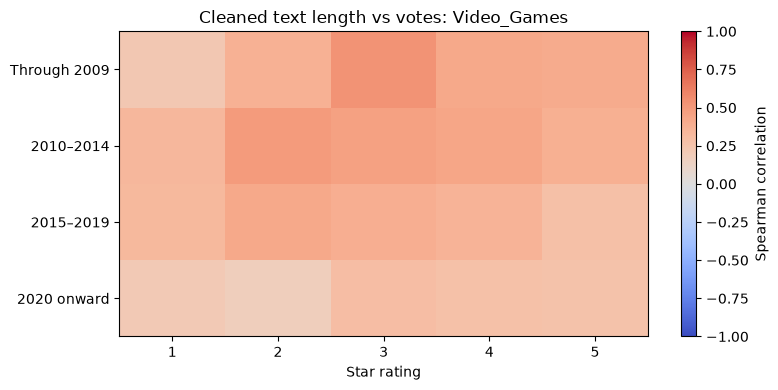

Correlations require at least 100 complete rows in each stratum.
The displayed associations do not adjust for all confounders or unequal vote exposure time.


In [17]:
MIN_STRATUM_N = 100
YEAR_PERIOD_LABELS = ["Through 2009", "2010–2014", "2015–2019", "2020 onward"]

strat = analysis_df.loc[
    analysis_df["review_year"].notna()
    & analysis_df["helpful_vote_num"].ge(0)
    & analysis_df["rating_num"].between(1, 5)
].copy()
strat["publication_period"] = pd.cut(
    strat["review_year"], bins=[-np.inf, 2009, 2014, 2019, np.inf],
    labels=YEAR_PERIOD_LABELS, include_lowest=True
)
strat["has_votes"] = strat["helpful_vote_num"].gt(0)
strat["log1p_votes"] = np.log1p(strat["helpful_vote_num"])

rating_within_period = (
    strat.groupby(["dataset_category", "publication_period", "rating_num"],
                  observed=True)
    .agg(n=("helpful_vote_num", "size"),
         nonzero_vote_rate=("has_votes", "mean"),
         mean_log1p_votes=("log1p_votes", "mean"),
         median_word_count=("text_word_count", "median"))
    .reset_index()
)
rating_within_period["sufficient_n_for_plot"] = rating_within_period["n"] >= MIN_STRATUM_N
display(rating_within_period)

for category in CATEGORIES:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    drawn = False
    for period in YEAR_PERIOD_LABELS:
        view = rating_within_period.loc[
            (rating_within_period["dataset_category"] == category)
            & (rating_within_period["publication_period"] == period)
            & rating_within_period["sufficient_n_for_plot"]
        ].sort_values("rating_num")
        if len(view) >= 2:
            ax.plot(view["rating_num"], view["nonzero_vote_rate"],
                    marker="o", label=period)
            drawn = True
    ax.set(title=f"Helpful-vote rate by rating within periods: {category}",
           xlabel="Star rating", ylabel="Fraction with ≥1 helpful vote")
    ax.set_xticks([1, 2, 3, 4, 5])
    if drawn:
        ax.legend(title="Publication period")
    else:
        ax.text(0.5, 0.5, "No large enough groups to plot",
                transform=ax.transAxes, ha="center")
    plt.tight_layout()
    plt.show()


def spearman_if_supported(df, x_col, y_col, min_n=MIN_STRATUM_N):
    pair = df[[x_col, y_col]].dropna()
    if len(pair) < min_n or pair[x_col].nunique() < 2 or pair[y_col].nunique() < 2:
        return np.nan
    return float(pair[x_col].corr(pair[y_col], method="spearman"))

period_rows = []
for (category, period), group in strat.groupby(
    ["dataset_category", "publication_period"], observed=True
):
    period_rows.append({
        "category": category, "publication_period": str(period),
        "n": len(group),
        "spearman_rating_vs_votes": spearman_if_supported(group, "rating_num", "helpful_vote_num"),
        "spearman_cleaned_words_vs_votes": spearman_if_supported(group, "text_word_count", "helpful_vote_num"),
        "nonzero_vote_rate": float(group["has_votes"].mean()),
    })
period_correlations = pd.DataFrame(period_rows)
display(period_correlations.round(3))

length_rows = []
for (category, period, rating), group in strat.groupby(
    ["dataset_category", "publication_period", "rating_num"], observed=True
):
    length_rows.append({
        "category": category, "publication_period": str(period),
        "rating": rating, "n": len(group),
        "spearman_cleaned_words_vs_votes": spearman_if_supported(
            group, "text_word_count", "helpful_vote_num"
        ),
        "nonzero_vote_rate": float(group["has_votes"].mean()),
        "median_word_count": float(group["text_word_count"].median()),
    })
length_within_rating_period = pd.DataFrame(length_rows)
display(length_within_rating_period.round(3))

for category in CATEGORIES:
    subset = length_within_rating_period.loc[
        length_within_rating_period["category"] == category
    ]
    matrix = subset.pivot_table(
        index="publication_period", columns="rating",
        values="spearman_cleaned_words_vs_votes", observed=True
    ).reindex(YEAR_PERIOD_LABELS)
    if matrix.empty or matrix.notna().sum().sum() == 0:
        print(f"No adequately sized length-vote strata for {category}")
        continue
    matrix = matrix.reindex(columns=[1, 2, 3, 4, 5])
    fig, ax = plt.subplots(figsize=(8, 4))
    img = ax.imshow(matrix.to_numpy(dtype=float), vmin=-1, vmax=1,
                    cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(5), labels=["1", "2", "3", "4", "5"])
    ax.set_yticks(range(4), labels=YEAR_PERIOD_LABELS)
    ax.set(title=f"Cleaned text length vs votes: {category}",
           xlabel="Star rating")
    fig.colorbar(img, ax=ax, label="Spearman correlation")
    plt.tight_layout()
    plt.show()

print(f"Correlations require at least {MIN_STRATUM_N} complete rows in each stratum.")
print("The displayed associations do not adjust for all confounders or unequal vote exposure time.")

## 7. Information Leakage Risk

A feature is unsafe if it contains the target itself, information created after the prediction point, or information from validation/test records that would not be available at deployment.

| Field or process | Leakage / evaluation risk | Planned mitigation |
|---|---|---|
| `helpful_vote` | It is the target itself. | Never include it among predictors. |
| Raw `user_id`, `asin`, `parent_asin` | A model may memorize repeated users/products; random row splits can put the same entity in train and test. | Use IDs for grouping and joins first. Evaluate user-disjoint and product-disjoint settings if cold-start generalization is claimed. |
| Reviewer/product activity counts computed on the full sample | Counts can include future reviews and validation/test records. | Build activity features from training history only and, for each review, only from earlier records. |
| Product `average_rating` / `rating_number` metadata | These may summarize reviews that include the target review or later reviews. | Exclude initially or recompute from training-only, time-valid history. |
| Product price and other snapshot metadata | The value may have changed after the review was written. | Document snapshot timing; use only if available at the intended prediction time. |
| Review timestamp | It may proxy how long the review had to accumulate votes. | Keep only if the prediction setting permits it; discuss exposure-time bias. |
| Duplicate or near-duplicate reviews | Copies can appear in different partitions and inflate performance. | Detect and group/deduplicate before splitting. |
| Text normalization / TF-IDF vocabulary / scaling / imputation | Fitting preprocessing on all data leaks validation/test distribution information. | Fit every preprocessing step on training data inside a pipeline. |
| Category-level target statistics | Computing category medians or encodings on all rows leaks held-out targets. | Estimate them using training data only. |

### Proposed split strategy

For the primary experiment, I'll use a **chronological holdout** after sorting by review timestamp (for example, oldest 70% for training, next 15% for validation, latest 15% for test). This aligns with evaluating later reviews and makes it possible to construct past-only activity features.

This split tests performance on later reviews from the observed marketplace population; it does **not** guarantee that reviewers or products are unseen. Therefore,I'll add separate product-disjoint and reviewer-disjoint stress tests if the intended claim includes cold-start prediction. A random row split alone may be optimistic because the same users and products can occur in multiple partitions.

The exact split percentages and cut dates should be frozen in the experiment protocol before model tuning. 

### Important target limitation

The dataset provides a recorded helpful-vote count but not the timestamp of each vote or a standardized exposure window. Therefore, this project can predict the **snapshot count**, but it cannot claim to predict votes received during the next 7/30 days unless a separate time-stamped voting dataset is obtained.

### Leakage-Aware Split Design

**Why can random row splitting be optimistic?** The same reviewer can write many reviews; a product may have many reviews; copies of a review can recur. A random train/test row split may therefore give a model a familiar user, product, or nearly identical text in its held-out set. This measures partly memorization rather than generalization to new entities. Fitting TF–IDF, imputers, encoders, or activity counts on the entire sample is also leakage.


- **Later reviews in the observed marketplace:** chronological review-level split (main planned evaluation) with time-valid feature engineering. This does **not** enforce unseen reviewers/products.
- **Unseen products:** group by `dataset_category + parent_asin` so every product stays in one partition. Unit = product group.
- **Unseen reviewers:** group by `user_id`, so all of a reviewer's reviews stay together. Unit = reviewer group.
- **No duplicated review leakage:** identical review fingerprints must stay together or be deduplicated *before* model training; the diagnostic below reports if copies cross a split.


**Critical target limitation:** A chronological split does not solve unequal exposure time by itself. For any eventual model, training-only/past-only activity features and train-only preprocessing are required.


## 8. Baseline Definition

### Primary baseline

**Training-set median predictor:** predict the median `helpful_vote` value from the training partition for every validation/test review. The median is a sensible first reference for a non-negative, usually skewed count target and is less sensitive to extreme counts than the mean.




### Planned feature-set comparison

| Model family | Inputs | Purpose |
|---|---|---|
| Text-only | Review title/body, TF–IDF word and character n-grams or text embeddings | Measure predictive information in review language. |
| Structured-only | Rating, verified purchase, valid time features, product metadata, and properly constructed past-only activity | Measure predictive information outside the review text. |
| Fused | Text + structured features | Test whether combining sources improves held-out performance. |
| Simple baseline | Training-set median | Provide a transparent reference point. |



## 9. Three Initial Questions and Final Question


### Question 1 — Predictive value of text and structured information

Can textual characteristics and structured information about a review, its reviewer, and its product predict the number of recorded helpful votes? Does combining text and structured features outperform either source alone?

### Question 2 — Incremental value of text

After accounting for rating, verified-purchase status, category, publication time, and available product context, do review-text characteristics (such as length, lexical patterns, and punctuation) show additional association with recorded helpful votes?

### Question 3 — Reviewer/product context and category differences

How are recorded helpful votes associated with reviewer activity, product activity, and category, and do these relationships differ between `Musical_Instruments` and `Video_Games`?

### Selected final research question

> **Can textual characteristics and structured information about a review, its reviewer, and its product predict the number of recorded helpful votes? Will combining text and structured features outperform either source alone?**

### Why this is the selected question

1. It is specific and directly connected to a real measurable outcome: the recorded `helpful_vote` count.
2. It uses multiple information sources rather than only one column or one modality.
3. It supports both required forms of work: exploratory association analysis (Objective A) and a controlled regression comparison (Objective B).
4. It naturally motivates fair baselines, modality ablation, leakage-aware splits, and error analysis in later phases.
5. It is feasible for both selected categories, subject to the actual field-availability and quality results produced by this notebook.
